# Decision Model: Wait or Ride On When a Citi Bike Station Is Full?

**The situation.** You ride up to your destination station to return a bike, and every dock is taken. You can **wait** for someone to take a bike out (which frees a dock), or **ride on** to a nearby station, which costs riding time there plus walking time back to where you were going.

**The question this notebook answers.** Can a simple probability model, built only from 2024 trip records, tell a rider which option gets them done sooner? And does following it beat simple rules of thumb when tested against what *actually* happened at real full stations?

### Why this framing (and not 30-minute forecasts)
The earlier project (`Final Notebook.ipynb`) measured net traffic per station in 30-minute windows, with the aim of forecasting it. The counts in a single window were too small and noisy for such forecasts to be operationally reliable. The decision here doesn't need the count in a window. It needs the **rate** at which bikes leave a station (departures per minute). A rate is an average over every comparable time slot in the year, so it is stable even when individual windows are noisy. Every probability below comes from that rate.

### The approach in one picture
| Step | Data | What it does |
|---|---|---|
| **Train** (Sections 2–4) | 2024 trip records, days 1–21 of every month | Estimate each station's departure rate by time of day, day type and weather |
| **Check 1** (Section 5) | Held-out trip records, days 22–end | Are the predicted probabilities of "at least one departure in the next *w* minutes" correct? |
| **Check 2: out-of-sample** (Section 7) | Station status snapshots (every 2 min), days 22–end | At moments when a station was **really** full, how long did it take for a dock to open, and did the model predict that? |
| **Recalibrate** (Section 8, optional) | Status snapshots, days 15–21 | Small 3-number correction for what trip data can't see (rebalancing trucks, other riders grabbing the freed dock) |
| **Decide** (Section 9) | Status snapshots, days 22–end | Replay thousands of real "arrived at a full station" moments and compare decision rules |

No model parameter is fitted on days 22–end of any month. Those days are only for testing.

### Key terms
- **Departure rate (λ)**: how many bikes are expected to be taken out of a station per unit of time (the model works in 30-minute slots). Each departure frees one dock.
- **Expected departures in a window (Λ)**: the rate added up over the window. With departures arriving at random (a *Poisson process*), **P(at least one dock opens within *w* minutes) = 1 − e^(−Λ)**.
- **Survival curve**: the probability that the station is *still* full *u* minutes after you arrive, plotted against *u*. Expected wait = area under this curve.
- **Calibrated**: when the model says 70%, it happens about 70% of the time.
- **Brier score**: average of (predicted probability − what happened)², lower is better. A fair coin guess scores 0.25.
- **Log loss**: like the Brier score, but punishes confident wrong predictions much more; lower is better.
- **Trip-based model**: the Section 4 model, built only from trip records. **Recalibrated model**: the same model after the 3-number correction in Section 8.

### Before running
1. **Environment**: Python 3.10+ (tested on 3.13) with the packages in `requirements.txt`. See *How to Run* in the README.
2. **Trip data**: the raw 2024 CSVs (the same files `Final Notebook` used; from [Citi Bike System Data](https://citibikenyc.com/system-data)). Set `TRIP_DATA_GLOB` in the config cell to where they are.
3. **Station status data** (Sections 6–9): `citi_bike_stations_2024.parquet` (4.2 GB) from the Kaggle dataset [rosenthal/citi-bike-stations](https://www.kaggle.com/datasets/rosenthal/citi-bike-stations). Section 6 downloads just this one file automatically with `kagglehub` if it isn't at `STATUS_PATH` yet. No Kaggle login is needed for this public dataset. (`data/` is in `.gitignore`.)
4. **Memory/time**: a full year of trips needs several GB of RAM (Section 2 loads only the columns it uses to keep this down). The one-time status cache in Section 6 takes a few minutes. Everything after that runs in minutes.

Lines marked `# CHANGED`, `# NEW` or `# NOTE` inside Section 2 are the only differences from `Final Notebook`. Everything else in that section is copied as-is.

## 1. Setup

In [1]:
import pandas as pd 
import numpy as np
import time 
import glob
import re
from datetime import datetime
import dateutil 
import holidays
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# NEW: imports used by the decision model
import os
import duckdb
from sklearn.linear_model import PoissonRegressor
from sklearn.neighbors import BallTree
from scipy.optimize import minimize

In [3]:
# ---------------- Paths ----------------
TRIP_DATA_GLOB   = "../CitiBike/data/**/*.csv"                     # raw 2024 trip CSVs (same files Final Notebook used)
STATUS_PATH      = "data/status/citi_bike_stations_2024.parquet"   # Kaggle: rosenthal/citi-bike-stations, 2024 file
STATUS_CACHE_DIR = "data/status/status_2024_slim"                   # small cache built from STATUS_PATH in Section 6
FIG_DIR          = "figures/decision_model"

# ---------------- Train / test split (by day of month, every month) ----------------
TRAIN_LAST_DAY  = 21   # days 1-21: trips used to fit the rate model
RECAL_FIRST_DAY = 15   # days 15-21: status snapshots used ONLY for the optional recalibration (Section 8)
TEST_FIRST_DAY  = 22   # days 22-end: held out; used only for testing
MONTHS          = list(range(1, 13))

# ---------------- Rate model ----------------
PRIOR_STRENGTH = 5     # how strongly sparse stations are pulled toward their overall daily pattern (in half-hour slots)
N_FIT_ROUNDS   = 3     # rounds of alternating between station patterns and the weather/season adjustment

# ---------------- Evaluation ----------------
STEP_MIN            = 2                 # status snapshots are 2 minutes apart, so time is measured in 2-minute steps
WINDOWS_MIN         = [2, 6, 10, 20]    # "will a dock open within w minutes?" is checked for these w
N_TRIP_QUERIES      = 300_000           # random (station, moment) checks for Section 5
PIT_HORIZON_MIN     = 120               # waiting-time check looks this far ahead
N_EVENTS_PER_BLOCK  = 20_000            # full-station moments sampled per month (Sections 7-8)
N_REPLAY_PER_BLOCK  = 5_000             # of those, how many are replayed through the decision rules (Section 9)

# ---------------- Decision model ----------------
NEIGHBOR_K        = 5      # consider up to K nearest other stations...
NEIGHBOR_RADIUS_M = 500    # ...but only within this straight-line distance (~6 short Manhattan blocks / 2 avenues)
DETOUR_FACTOR     = 1.3    # street distance is about 1.3x straight-line distance on a grid
BIKE_SPEED_M_MIN  = 200    # ~12 km/h riding
WALK_SPEED_M_MIN  = 80     # ~4.8 km/h walking
MAX_WAIT_MIN      = 60     # waits are counted up to 60 minutes (longer waits count as 60)
LONG_WAIT_MIN     = 15     # a total time above this counts as a "long" outcome in the Section 9 summary
NEIGHBOR_PRIOR_SNAPSHOTS = 30   # shrinkage for P(neighbor full | station full), in snapshots (30 = 1 hour)

SEED = 42
rng = np.random.default_rng(SEED)
os.makedirs(FIG_DIR, exist_ok=True)

N_STEPS   = MAX_WAIT_MIN // STEP_MIN    # number of 2-minute steps in the wait horizon
LAM_FLOOR = 1e-3                        # keeps log(expected departures) finite at stations with ~zero predicted demand

In [4]:
# Plot style: recessive axes/grid, one fixed color order for series
INK, INK_SECONDARY, GRID_COLOR = "#0b0b0b", "#52514e", "#e4e3df"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # blue, orange, aqua, yellow (always in this order)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_SECONDARY, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 2. Preprocessing (reused from `Final Notebook`)

Same cleaning steps as before: normalize ride ids, parse timestamps, drop rows without a station, keep rides present as both a departure and an arrival, then count departures (`df_exits_final`) and arrivals (`df_enter_final`) per station per 30 minutes.

The additions, marked `# CHANGED` / `# NEW`:
- load only the **7 columns** this notebook uses (about 40% less memory), and free each raw table as soon as it's no longer needed. A full year of trips is large for a 16 GB machine;
- keep **one coordinate per station**, for finding neighboring stations;
- keep the **exact departure timestamps** before they're binned, because Section 5 checks predictions minute by minute.

In [5]:
#Loading raw data into the notebook

# NEW: only the 7 columns this notebook uses (about 40% less memory than all 13)
TRIP_COLUMNS = ['ride_id', 'started_at', 'ended_at', 'start_station_name', 'end_station_name', 'start_lat', 'start_lng']

csv_files = glob.glob(TRIP_DATA_GLOB, recursive=True)   # CHANGED: path comes from the config cell
dfs_2024 = [pd.read_csv(file, low_memory = False, usecols = TRIP_COLUMNS) for  file in csv_files]   # CHANGED: usecols
df = pd.concat(dfs_2024, ignore_index= True)
del dfs_2024   # NEW: the per-file tables aren't needed once combined

In [6]:
#Ensuring all rides are of the same type

df['ride_id'] = df['ride_id'].astype(str).str.strip().str.lower()
df.head()

,ride_id,started_at,ended_at,start_station_name,end_station_name,start_lat,start_lng
0,c40e88bb937bdc15,2024-09-26 09:06:40.740,2024-09-26 09:27:55.009,Columbia St & Degraw St,6 Ave & Canal St,40.685930,-74.002424
1,f9db9fb8df1b9698,2024-09-15 16:36:01.749,2024-09-15 16:50:41.891,Kent Ave & Grand St,Pike St & E Broadway,40.716425,-73.965940
2,2c876366cd11d036,2024-09-24 22:44:19.582,2024-09-24 22:59:35.506,W 67 St & Broadway,Central Park North & Adam Clayton Powell Blvd,40.774925,-73.982666
3,d639068ac8d3de4d,2024-09-16 16:39:05.447,2024-09-16 17:02:05.830,Madison Ave & E 82 St,Central Park North & Adam Clayton Powell Blvd,40.778131,-73.960694
4,7c1b06cfc9849b71,2024-09-30 15:45:18.183,2024-09-30 15:46:42.613,Lafayette Ave & St James Pl,Willoughby Ave & Hall St,40.688515,-73.964763


In [7]:
#Dropping duplicate rides

print(df['ride_id'][df['ride_id'].duplicated(keep=False)])
df['ride_id'].drop_duplicates()

# NOTE: the line above displays de-duplicated ids but does not change df (same as Final Notebook).

Series([], Name: ride_id, dtype: object)


0           c40e88bb937bdc15
1           f9db9fb8df1b9698
2           2c876366cd11d036
3           d639068ac8d3de4d
4           7c1b06cfc9849b71
                  ...       
44303204    c049c1fb462707cd
44303205    d7102bd6283d129f
44303206    e548ac67537f0fe5
44303207    7f74fc8b7a9dd81a
44303208    4494283bfacb7e37
Name: ride_id, Length: 44303209, dtype: object

In [8]:
#Creating Dataframes for enters and exits

df_exits = df[['ride_id', 'started_at', 'start_station_name']].copy()
df_enter = df[['ride_id', 'ended_at', 'end_station_name']].copy()

In [9]:
# NEW: one location per station = median of its trip start coordinates.
# (E-bike trips record GPS positions that scatter around the dock; the median is robust to that.)
station_coords = (
    df.groupby('start_station_name')[['start_lat', 'start_lng']]
    .median()
    .rename(columns={'start_lat': 'lat', 'start_lng': 'lon'})
)
print(f"{len(station_coords):,} stations with coordinates")

# NEW: everything below works on df_exits / df_enter, so the full ride table can be freed now
del df

2,273 stations with coordinates


In [10]:
#Fixing the dates in order to convert to datetime

exits_count = df_exits.shape[0]
enter_count = df_enter.shape[0]
print(f"before to datetime ride number for exits: {exits_count}" )
print(f"before to datetime ride number for arrival: {enter_count}" )

#STRIPPING THE TIMES TO CONVERT TO DATETIME

#Normalize & strip invisibles for exits
df_exits['started_at'] = (
    df_exits['started_at']
    .astype(str).str.strip()
    .str.replace('\u00A0', ' ', regex=False)
    .str.replace('\u200B', '',  regex=False)
)

#Crop anything past 19 chars
df_exits['started_at'] = df_exits['started_at'].str.replace(
    r'(^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}).*$', 
    r'\1', 
    regex=True
)
df_enter['ended_at'] = (
    df_enter['ended_at']
    .astype(str).str.strip()
    .str.replace('\u00A0', ' ', regex=False)
    .str.replace('\u200B', '',  regex=False)
    .str.replace(
        r'(^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}).*$', 
        r'\1', 
        regex=True
    )
)

#Parse with explicit format and convert dates to formal datetime index

df_exits['started_at'] = pd.to_datetime(
    df_exits['started_at'], 
    format='%Y-%m-%d %H:%M:%S', 
    errors='coerce'
)

df_enter['ended_at'] = pd.to_datetime(
    df_enter['ended_at'], 
    format='%Y-%m-%d %H:%M:%S', 
    errors='coerce'
)

print(f"after strip and datetime exits: {df_exits.shape[0]}")
print(f"after strip and datetime enter: {df_enter.shape[0]}")

#Verify that there aren't any NAT
print("Failed exits:", df_exits['started_at'].isna().sum())
print("Failed enters:", df_enter['ended_at'].isna().sum())

before to datetime ride number for exits: 44303209
before to datetime ride number for arrival: 44303209
after strip and datetime exits: 44303209
after strip and datetime enter: 44303209
Failed exits: 0
Failed enters: 0


In [11]:
# DROPS NAT IF IT EXISTS AND SETS DATETIME INDEX
df_exits = df_exits.dropna(subset=['started_at'])
df_enter = df_enter.dropna(subset=['ended_at'])

df_exits = df_exits.set_index('started_at')
df_enter = df_enter.set_index('ended_at')

In [12]:
#Printing and dropping NAN values in both departure and arrival dataframes

print(f"count for NAN values in start station names: {df_exits['start_station_name'].isna().sum()}")
print(f"count for NAN values in end station names: {df_enter['end_station_name'].isna().sum()}")

df_exits = df_exits.dropna(subset='start_station_name')
df_enter = df_enter.dropna(subset='end_station_name')

count for NAN values in start station names: 29835
count for NAN values in end station names: 114545


In [13]:
# DROP ANY RIDES THAT AREN'T PRESENT IN BOTH DATAFRAMES

df_exits = df_exits[df_exits['ride_id'].isin(df_enter['ride_id'])]
df_enter = df_enter[df_enter['ride_id'].isin(df_exits['ride_id'])]

print(df_exits.shape[0])
print(df_enter.shape[0])

44173378
44173378


In [14]:
# NEW: keep the exact (un-binned) departure times. The next cell bins departures into 30-minute counts,
# but Section 5 checks "was there a departure within w minutes of this moment?", which needs exact times.
departure_times = df_exits['start_station_name'].copy()        # index = started_at, value = station name
departure_times = departure_times[departure_times.index.year == 2024]
print(f"{len(departure_times):,} departures in 2024")

44,173,014 departures in 2024


In [15]:
#Grouping data by stations to show number of rides per station at each time

print(f"number of rows without station name exits: {df_exits['start_station_name'].isna().sum()}")
print(f"number of rows without station name enter: {df_enter['end_station_name'].isna().sum()}")

df_exits = df_exits.groupby('start_station_name').resample('30min')['ride_id'].count()
df_enter = df_enter.groupby('end_station_name').resample('30min')['ride_id'].count()


print(f"after resampling and grouping by stations exits: {df_exits.shape[0]}")
print(f"after resampling and grouping by stations enter: {df_enter.shape[0]}")

number of rows without station name exits: 0
number of rows without station name enter: 0
after resampling and grouping by stations exits: 37558550
after resampling and grouping by stations enter: 38437665


In [16]:
#Unstacking dataframe making stations as columns so it is easier to analyze

df_exits_final = df_exits.unstack(level='start_station_name', fill_value=0)
df_exits_final.head(30)

start_station_name,1 Ave & E 110 St,1 Ave & E 118 St,1 Ave & E 16 St,1 Ave & E 18 St,1 Ave & E 30 St,1 Ave & E 38 St,1 Ave & E 39 St,1 Ave & E 42 St,1 Ave & E 44 St,1 Ave & E 6 St,...,Woodward Ave & Harman St,Woodward Ave & Starr St,Wyckoff Ave & Cooper Ave,Wyckoff Ave & Gates Ave,Wyckoff Ave & Jefferson St,Wyckoff Ave & Stanhope St,Wyckoff St & 3 Ave,Wythe Ave & Metropolitan Ave,Wythe Ave & N 13 St,Yankee Ferry Terminal
started_at,,,,,,,,,,,,,,,,,,,,,
2023-12-31 13:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 14:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 14:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 15:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 15:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 16:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 16:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 17:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 17:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [17]:
#Unstacking dataframe making stations as columns so it is easier to analyze

df_enter_final = df_enter.unstack(level='end_station_name', fill_value=0)
df_enter_final.head(30)

end_station_name,1 Ave & E 110 St,1 Ave & E 118 St,1 Ave & E 16 St,1 Ave & E 18 St,1 Ave & E 30 St,1 Ave & E 38 St,1 Ave & E 39 St,1 Ave & E 42 St,1 Ave & E 44 St,1 Ave & E 6 St,...,Woodward Ave & Starr St,Wyckoff Ave & Cooper Ave,Wyckoff Ave & Gates Ave,Wyckoff Ave & Jefferson St,Wyckoff Ave & Stanhope St,Wyckoff St & 3 Ave,Wythe Ave & Metropolitan Ave,Wythe Ave & N 13 St,Yankee Ferry Terminal,York St & Marin Blvd
ended_at,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,0,0,0,0,0,0,2,0,0,2,...,0,0,0,0,0,1,1,0,0,0
2024-01-01 00:30:00,2,0,2,2,2,0,5,0,0,5,...,0,1,1,0,0,0,0,0,0,0
2024-01-01 01:00:00,1,0,0,3,1,0,3,0,1,7,...,0,3,1,4,1,1,2,1,0,0
2024-01-01 01:30:00,0,0,2,0,1,0,0,0,1,1,...,0,0,0,3,2,0,2,0,0,0
2024-01-01 02:00:00,0,0,1,3,3,0,2,0,0,2,...,0,0,2,4,5,0,2,0,0,0
2024-01-01 02:30:00,0,0,2,3,0,0,2,0,0,1,...,0,1,1,0,1,0,3,0,0,0
2024-01-01 03:00:00,1,0,0,2,2,0,2,0,0,1,...,0,0,1,1,0,0,0,0,0,0
2024-01-01 03:30:00,1,0,0,1,2,0,2,0,0,2,...,0,0,1,0,0,0,1,0,0,0
2024-01-01 04:00:00,1,0,2,0,1,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,0


In [18]:
# NEW: the 30-minute counts are now in df_exits_final / df_enter_final; free the per-ride series
del df_exits, df_enter

### Weather (reused, with one fix)
Same Meteostat pull as `Final Notebook`, with one correction. Meteostat returns timestamps in **UTC**, while trip timestamps are **New York local time**. The original join therefore matched weather to rides 4–5 hours off (2pm rain landed on 6–7pm rides). Here the weather index is converted to New York time first. Two small lines support that: the end date is extended 6 hours so Dec 31 evening is still covered, and the 1am hour that repeats when clocks fall back is dropped. The next cell (30-minute resampling) is unchanged.

In [19]:
#Importing weather features
from meteostat import Hourly, Point

# Central Park coordinates
cp = Point(40.7812, -73.9665)

start = datetime(2024, 1, 1, 0)
end   = datetime(2025, 1, 1, 6)   # CHANGED: was datetime(2025, 1, 1, 0); extra hours cover Dec 31 evening after the time-zone fix below

# Fetch hourly data
weather_df = Hourly(cp, start, end).fetch()
# NEW: Meteostat timestamps are UTC; trip timestamps are New York local time. Convert so weather lines up with rides.
weather_df.index = weather_df.index.tz_localize("UTC").tz_convert("America/New_York").tz_localize(None)
weather_df = weather_df[~weather_df.index.duplicated(keep="first")]   # clocks fall back once a year and repeat 1am
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8790 entries, 2023-12-31 19:00:00 to 2025-01-01 01:00:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    8790 non-null   Float64
 1   dwpt    8790 non-null   Float64
 2   rhum    8790 non-null   Float64
 3   prcp    8784 non-null   Float64
 4   snow    0 non-null      Float64
 5   wdir    8790 non-null   Float64
 6   wspd    8790 non-null   Float64
 7   wpgt    0 non-null      Float64
 8   pres    8790 non-null   Float64
 9   tsun    0 non-null      Float64
 10  coco    8784 non-null   Float64
dtypes: Float64(11)
memory usage: 918.5 KB


In [20]:
# Rename and slice columns while keeping temp, precipitation, and wind speed. Also creates boolean column to check if raining

weather_df = (
    weather_df.rename(columns={
        "temp": "temp_c",        # °C
        "prcp": "precip_mm",     # mm
        "wspd": "wind_speed",      # km/h
    })[["temp_c", "precip_mm", "wind_speed"]].copy()
)

precip_col = weather_df.precip_mm.resample('30min').ffill() / 2

temp_col = weather_df.temp_c.resample('30min').interpolate('time')

wind_col = weather_df.wind_speed.resample('30min').ffill()

weather_df = pd.concat([precip_col, temp_col, wind_col], axis=1)

weather_df["is_raining"] = (weather_df["precip_mm"].fillna(0) > 0).astype(int)

weather_df = weather_df.loc["2024-01-01":"2024-12-31 23:30"]

weather_df['temp_f'] = weather_df['temp_c'] * 9/5 + 32

weather_df.drop('temp_c', axis=1, inplace=True)

# Save clean CSV (index is the timestamp)
print(weather_df.shape[0])

17568


### Calendar features (reused)
Three similarly named objects come out of these cells:
- `dates`: every half-hour of 2024 (17,568 timestamps);
- `dates_df`: True/False for each of those half-hours, True on US holidays;
- `days_dates_df`: weekend flag, day of week and month for each half-hour.

In [21]:
#Creating 'dates' column that represents US National Holidays 

dates = pd.date_range('2024-01-01 00:00', '2024-12-31 23:30', freq="30min")
dates_df = dates.to_series().dt.date.isin(holidays.US(years=2024))
dates_df.shape[0]

17568

In [22]:
#Adding is_weekend column to show if day is weekend or not
# CHANGED: built on the full 2024 calendar (`dates`) instead of net_traffic_df's index, which this notebook doesn't create

is_weekend_col = pd.Series(dates.dayofweek >= 5, index=dates, name= 'is_weekend')
day_col = pd.Series(dates.dayofweek, index=dates, name='day of week')
month_col = pd.Series(dates.month, index=dates, name='month')
print(is_weekend_col.shape[0])
print(day_col.shape[0])
print(month_col.shape[0])

17568
17568
17568


In [23]:
# #Adding Day of Week and Month 

days_dates_df = pd.concat([is_weekend_col, day_col, month_col], axis=1)
print(f"days and dates len: {days_dates_df.shape[0]}")
print(f"weather len: {weather_df.shape[0]}")
print(f"holidays len: {dates_df.shape[0]}")

days and dates len: 17568
weather len: 17568
holidays len: 17568


In [24]:
dates_df.name = 'holidays'   # NEW here (Final Notebook set this name in its join cell)

## 3. Arrange the data for modeling

Everything from here is new. The model works on plain arrays:

| Name | Shape | Meaning |
|---|---|---|
| `Y` | slots × stations | departures in each 30-minute slot of 2024 (17,568 slots) |
| `active` | slots × stations | True in months where the station had at least one departure on that month's training days |
| `profile_key` | slots | which of 96 calendar profiles a slot belongs to: 48 half-hours × {workday, weekend/holiday} |
| `is_train`, `is_test` | slots | day of month ≤ 21, or ≥ 22 |
| `X` | slots × features | weather and season for each slot |
| `dep_key` | departures | every exact departure time, sorted by station then time (for fast lookups) |

Times are measured as **minutes since 2024-01-01 00:00 New York time** throughout.

In [25]:
# Departures per station per 30-minute slot, for every slot of 2024 (slots with no rides = 0)
departures = df_exits_final[df_exits_final.index.year == 2024].reindex(dates, fill_value=0)

stations = departures.columns.to_numpy()                  # station names; a station's position here is its index everywhere below
station_idx = {name: i for i, name in enumerate(stations)}
Y = departures.to_numpy(dtype=np.float32)                 # shape (n_slots, n_stations)
n_slots, n_stations = Y.shape

# Train / test split by day of month
is_train = np.asarray(dates.day <= TRAIN_LAST_DAY)
is_test = np.asarray(dates.day >= TEST_FIRST_DAY)

# A station counts as existing in a month if it had at least one departure on that month's TRAINING days.
# So a station that opened in June isn't treated as having zero demand in January, and nothing about
# the test days is used to decide which stations exist.
month_of_slot = np.asarray(dates.month) - 1
exists_in_month = np.stack([(Y[is_train & (month_of_slot == m)] > 0).any(axis=0) for m in range(12)])   # (12, n_stations)
active = exists_in_month[month_of_slot]                                                                # (n_slots, n_stations)

# Calendar profile of each slot: 48 half-hours x {workday, weekend/holiday} = 96 profiles
slot_of_day = np.asarray(dates.hour * 2 + dates.minute // 30)
is_offday = (days_dates_df['is_weekend'] | dates_df).to_numpy()
profile_key = is_offday.astype(int) * 48 + slot_of_day

print(f"{n_stations:,} stations x {n_slots:,} half-hour slots")
print(f"train slots: {is_train.sum():,}   test slots: {is_test.sum():,}")
print(f"departures in train: {Y[is_train].sum():,.0f}   in test: {Y[is_test].sum():,.0f}")

2,273 stations x 17,568 half-hour slots
train slots: 12,096   test slots: 5,472
departures in train: 30,845,536   in test: 13,327,479


In [26]:
# Exact departure times, packed as (station index x KEY_SCALE + minute) and sorted.
# Because KEY_SCALE is larger than the number of minutes in a year, sorting this one number sorts by
# station first and then by time, so "departures at station s between t1 and t2" is two binary searches.
YEAR_START = pd.Timestamp("2024-01-01")
KEY_SCALE = 1_000_000

dep_station = pd.Categorical(departure_times.to_numpy(), categories=stations).codes.astype(np.int64)
assert (dep_station >= 0).all(), "every departure should belong to a known station"
dep_min = ((departure_times.index - YEAR_START) / pd.Timedelta(minutes=1)).to_numpy()
dep_key = np.sort(dep_station * KEY_SCALE + dep_min)
del departure_times, dep_station, dep_min
print(f"{len(dep_key):,} exact departure times indexed")

44,173,014 exact departure times indexed


In [27]:
# Weather + season features for every slot. Each feature acts as a multiplier on all stations' departure rates.
TEMP_BINS = [-np.inf, 35, 45, 55, 65, 75, 85, np.inf]
TEMP_LABELS = ["<35F", "35-45F", "45-55F", "55-65F", "65-75F", "75-85F", ">85F"]
N_SEASON_WAVES = 3      # sine/cosine pairs for the seasonal curve (1 = one bump per year; more = more flexible)

# Smooth seasonal curve: sine/cosine waves of the time of year. Captures what weather alone doesn't
# (daylight, tourism, school calendar), and changes smoothly across the held-out days 22-end of each month.
year_fraction = (np.asarray(dates.day_of_year) - 1 + np.asarray(dates.hour) / 24) / 366
season_features = pd.DataFrame(
    {f"season_{fn.__name__}{k}": fn(2 * np.pi * k * year_fraction) for k in range(1, N_SEASON_WAVES + 1) for fn in (np.sin, np.cos)},
    index=dates,
)

w = weather_df.reindex(dates).ffill().bfill()
weather_features = pd.concat([
    w["is_raining"].rename("raining"),
    # capped at 10 mm per half hour (rare) so a few storms don't dominate the fit
    np.log1p(w["precip_mm"].fillna(0).clip(upper=10)).rename("log_precip_mm"),
    (w["wind_speed"] / 10).rename("wind_per_10kmh"),
    # temperature in bins, compared against a comfortable 65-75F
    pd.get_dummies(pd.cut(w["temp_f"], TEMP_BINS, labels=TEMP_LABELS), prefix="temp").drop(columns="temp_65-75F"),
    season_features,
], axis=1).astype(float)
X = weather_features.to_numpy()
weather_features.head()

,raining,log_precip_mm,wind_per_10kmh,temp_<35F,temp_35-45F,temp_45-55F,temp_55-65F,temp_75-85F,temp_>85F,season_sin1,season_cos1,season_sin2,season_cos2,season_sin3,season_cos3
2024-01-01 00:00:00,1.0,0.04879,1.10,0.0,1.0,0.0,0.0,0.0,0.0,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2024-01-01 00:30:00,1.0,0.04879,1.10,0.0,1.0,0.0,0.0,0.0,0.0,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2024-01-01 01:00:00,0.0,0.00000,0.70,0.0,1.0,0.0,0.0,0.0,0.0,0.000715,1.000000,0.001431,0.999999,0.002146,0.999998
2024-01-01 01:30:00,0.0,0.00000,0.70,0.0,1.0,0.0,0.0,0.0,0.0,0.000715,1.000000,0.001431,0.999999,0.002146,0.999998
2024-01-01 02:00:00,0.0,0.00000,0.68,0.0,1.0,0.0,0.0,0.0,0.0,0.001431,0.999999,0.002861,0.999996,0.004292,0.999991


## 4. The rate model (trained on trips only)

For station $s$ in 30-minute slot $t$, the expected number of departures in that slot is:

$$\lambda_{s,t} \;=\; \underbrace{\text{base}_s(\text{profile}_t)}_{\text{station's normal pattern}} \;\times\; \underbrace{m_t}_{\text{weather \& season}}$$

Within a slot, departures are assumed to arrive at a steady rate (λ/30 per minute). That's how the model answers questions about windows of any length, such as 2 or 10 minutes.

- **base** is the station's average departures in that half-hour, on that kind of day (workday or weekend/holiday). It's estimated separately for every station, because a Midtown commuter hub and a Queens residential corner have different daily shapes. Stations with little data are pulled gently toward their own overall average, shaped by the system-wide daily pattern (`PRIOR_STRENGTH`).
- **$m_t$** is one multiplier per slot, shared by all stations: rain, precipitation amount, wind, temperature band, and a smooth seasonal curve over the year. It's fitted with a **Poisson regression**, so each weather coefficient reads as "multiplies departures by X". The seasonal curve is a few sine/cosine waves rather than one value per month. Training covers days 1–21 of *every* month, so a smooth curve can follow demand rising through spring and falling through fall, including across the held-out days 22–end. A one-value-per-month step can't.

**Why the weather fit can use system-wide totals.** Because $m_t$ is shared, the best-fitting weather coefficients only depend on the *total* observed vs. *total* expected departures per slot. So the regression has one row per half-hour (≈12,000 training rows) instead of one per station-slot (≈26 million), and gives the same answer.

The two parts depend on each other (the base is "normal weather" demand, and the weather effect is measured relative to the base). So they are fitted by alternating: estimate the base given the weather effect, then the weather effect given the base, for `N_FIT_ROUNDS = 3` rounds. The printed "largest change" should be close to 0 by the last round. If it isn't, raise `N_FIT_ROUNDS`.

In [28]:
def fit_base_rates(Y, active, use_slot, profile_key, multiplier, prior_strength=PRIOR_STRENGTH):
    """Each station's expected departures per 30-min slot, for each of the 96 calendar profiles,
    after dividing out the weather/season multiplier. Shape (96, n_stations).

    Sparse station-profiles are shrunk toward prior = station's overall average x system-wide profile shape,
    as if `prior_strength` extra slots had been observed at the prior rate."""
    n_keys = 96
    observed = np.zeros((n_keys, Y.shape[1]))
    exposure = np.zeros((n_keys, Y.shape[1]))     # number of slots observed, weighted by the multiplier
    for k in range(n_keys):
        rows = np.flatnonzero(use_slot & (profile_key == k))
        is_open = active[rows]
        observed[k] = (Y[rows] * is_open).sum(axis=0)
        exposure[k] = (multiplier[rows, None] * is_open).sum(axis=0)

    station_total = exposure.sum(axis=0)
    station_rate = np.divide(observed.sum(axis=0), station_total, out=np.zeros(Y.shape[1]), where=station_total > 0)
    expected_by_profile = (exposure * station_rate).sum(axis=1)
    profile_shape = np.divide(observed.sum(axis=1), expected_by_profile, out=np.ones(n_keys), where=expected_by_profile > 0)
    prior = profile_shape[:, None] * station_rate[None, :]

    return ((observed + prior_strength * prior) / (exposure + prior_strength)).astype(np.float32)


def fit_weather_multiplier(Y, active, use_slot, profile_key, base, X):
    """Poisson regression of total observed departures per slot on weather/season features,
    with the base model's total expected departures as the exposure.
    (Fitting observed/expected with weight = expected is the standard way to fit an exposure offset in sklearn.)"""
    expected_total = (base[profile_key] * active).sum(axis=1)
    observed_total = (Y * active).sum(axis=1)
    rows = use_slot & (expected_total > 0)
    model = PoissonRegressor(alpha=1e-4, solver="newton-cholesky", max_iter=300)
    model.fit(X[rows], observed_total[rows] / expected_total[rows], sample_weight=expected_total[rows])
    return model

In [29]:
multiplier = np.ones(n_slots)
for round_number in range(1, N_FIT_ROUNDS + 1):
    base = fit_base_rates(Y, active, is_train, profile_key, multiplier)
    if round_number == 1:
        base_time_only = base.copy()      # time-of-day-only model (no weather), kept for comparison in Section 5
    weather_model = fit_weather_multiplier(Y, active, is_train, profile_key, base, X)
    new_multiplier = weather_model.predict(X)
    print(f"round {round_number}: largest change in the weather/season multiplier = {np.abs(new_multiplier - multiplier).max():.3f}")
    multiplier = new_multiplier

base = fit_base_rates(Y, active, is_train, profile_key, multiplier)   # final station patterns given the final multiplier

round 1: largest change in the weather/season multiplier = 0.793
round 2: largest change in the weather/season multiplier = 0.053
round 3: largest change in the weather/season multiplier = 0.011


**Reading the weather effects.** Each number multiplies every station's departure rate, compared with an otherwise identical half-hour that is **dry, 65–75°F, with no wind**. 1.00 means no difference, and 0.70 means 30% fewer departures. `raining` is the jump from dry to any rain, and `log_precip_mm` adds more for heavier rain (per unit of log(1 + mm per half hour)). Wind is per 10 km/h. The seasonal sine/cosine terms aren't meaningful one at a time, so they're shown together as a curve in the next cell.

In [30]:
coefficients = pd.Series(weather_model.coef_, index=weather_features.columns)
weather_terms = [name for name in coefficients.index if not name.startswith("season_")]
effects = np.exp(coefficients[weather_terms]).rename("multiplies departures by").round(2).to_frame()
effects

,multiplies departures by
raining,0.78
log_precip_mm,0.67
wind_per_10kmh,0.98
temp_<35F,0.55
temp_35-45F,0.67
temp_45-55F,0.77
temp_55-65F,0.90
temp_75-85F,1.09
temp_>85F,1.04


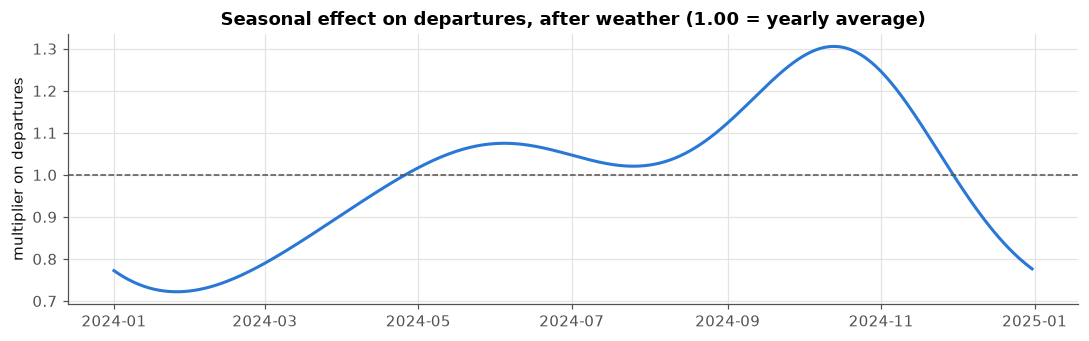

In [31]:
# The fitted seasonal curve: how much busier or quieter the system is at each point of the year (1.00 = yearly average),
# after accounting for weather. Training days are days 1-21 of each month; the curve fills in days 22-end smoothly.
season_terms = [name for name in coefficients.index if name.startswith("season_")]
seasonal_multiplier = np.exp(season_features[season_terms].to_numpy() @ coefficients[season_terms].to_numpy())
seasonal_multiplier = pd.Series(seasonal_multiplier / seasonal_multiplier.mean(), index=dates).resample("D").mean()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(seasonal_multiplier.index, seasonal_multiplier.to_numpy(), color=SERIES_COLORS[0])
ax.axhline(1, linestyle="--", color=INK_SECONDARY, linewidth=1)
ax.set_ylabel("multiplier on departures")
ax.set_title("Seasonal effect on departures, after weather (1.00 = yearly average)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/seasonal_effect.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
# Expected departures in every 30-min slot (rows) at every station (columns), and their running total.
lam_slot = base[profile_key] * multiplier[:, None].astype(np.float32) * active
cum_expected = np.zeros((n_slots + 1, n_stations))
np.cumsum(lam_slot, axis=0, dtype=np.float64, out=cum_expected[1:])   # cum_expected[i, s] = expected departures before slot i


def _expected_since_year_start(station, t_min):
    """Expected departures at `station` from 2024-01-01 00:00 up to t_min (rate is constant within each half hour)."""
    t_min = np.clip(t_min, 0, n_slots * 30 - 1e-6)
    slot = (t_min // 30).astype(np.int64)
    return cum_expected[slot, station] + (t_min - 30 * slot) / 30 * lam_slot[slot, station]


def expected_departures(station, start_min, duration_min):
    """Λ: expected number of departures at `station` between start_min and start_min + duration_min.
    Accepts numpy arrays (they broadcast). Times are minutes since 2024-01-01 00:00 New York time."""
    station = np.asarray(station)
    start_min = np.asarray(start_min, dtype=float)
    return _expected_since_year_start(station, start_min + duration_min) - _expected_since_year_start(station, start_min)


def survival_curves(station, t_min, elapsed_min=0.0, recal=None):
    """Probability a full station is STILL full u minutes after t_min, for u = 0, 2, 4, ..., MAX_WAIT_MIN.
    Returns shape (n, N_STEPS + 1); column k is u = 2k minutes.

    recal=None  -> trip-based model: a dock opens with every departure, so P(still full) = exp(-Λ).
    recal=(a,b,c) -> recalibrated model from Section 8 (uses how long the station has already been full)."""
    station = np.asarray(station)[:, None]
    steps = np.arange(N_STEPS)[None, :]
    step_start = np.asarray(t_min, dtype=float)[:, None] + STEP_MIN * steps
    hazard = expected_departures(station, step_start, STEP_MIN)          # expected dock openings in each 2-min step
    if recal is not None:
        a, b, c = recal
        elapsed = np.asarray(elapsed_min, dtype=float).reshape(-1, 1) + STEP_MIN * steps
        hazard = np.exp(a + b * np.log(hazard + LAM_FLOOR) + c * np.log1p(elapsed))
    cumulative = np.concatenate([np.zeros((hazard.shape[0], 1)), np.cumsum(hazard, axis=1)], axis=1)
    return np.exp(-cumulative)


def expected_wait(survival):
    """Expected minutes until a dock opens (counting at most MAX_WAIT_MIN) = area under the survival curve."""
    return np.trapezoid(survival, dx=STEP_MIN, axis=1)

**Sanity check.** Model vs. reality for the busiest station during one held-out week. The line is the model's expected departures per half hour, and the dots are what actually happened. **What passing looks like:** the line rises and falls at the same hours as the dots, and the dots are spread evenly above and below it. They won't sit *on* the line, because single half-hours are noisy. That noise is why the earlier 30-minute forecasts couldn't be used operationally. The model doesn't try to predict the noise; Sections 5 and 7 check whether it gets the *probabilities* right.

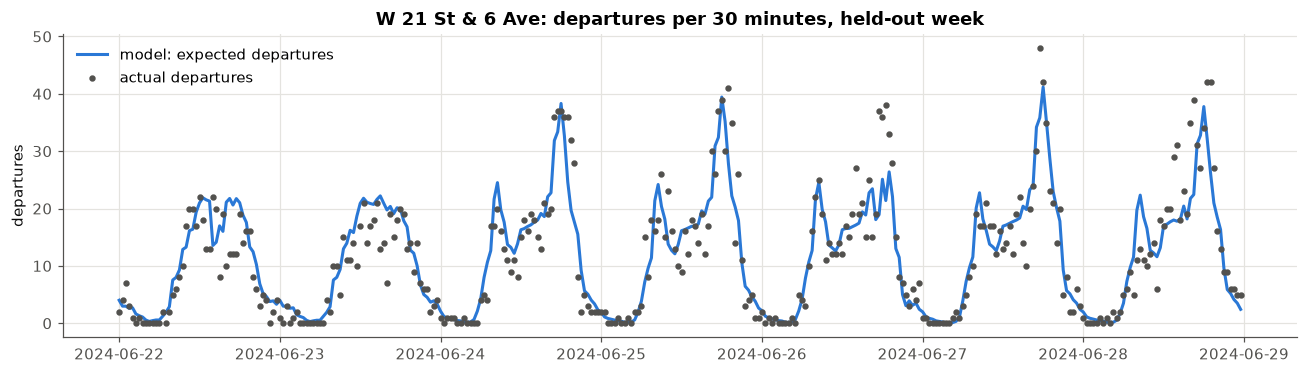

In [33]:
busiest = int(np.argmax(Y[is_train].sum(axis=0)))
week = np.flatnonzero((dates >= "2024-06-22") & (dates < "2024-06-29"))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(dates[week], lam_slot[week, busiest], color=SERIES_COLORS[0], label="model: expected departures")
ax.scatter(dates[week], Y[week, busiest], s=10, color=INK_SECONDARY, label="actual departures", zorder=3)
ax.set_title(f"{stations[busiest]}: departures per 30 minutes, held-out week")
ax.set_ylabel("departures")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/model_vs_actual_week.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Check 1: are the probabilities right? (held-out trip records)

We pick 300,000 random (station, moment) pairs from the **test days** and a window $w$ of 2, 6, 10 or 20 minutes. For each:
- **prediction**: P(at least one departure in the next $w$ minutes) $= 1 - e^{-\Lambda}$;
- **outcome**: did a departure actually happen? This is looked up exactly in the raw timestamps, with no binning.

Three models are compared, to see what each ingredient adds:
1. **Station average**: one constant rate per station (no time of day, no weather or season).
2. **Time of day**: the station's pattern by half-hour and day type (no weather or season).
3. **Time of day + weather/season**: the full trip-based model from Section 4.

**Caveat.** These moments are random, not moments when the station was full. Some of them are moments when the station was *empty*, when no one can take a bike out no matter how many want to. Trip records can't tell those apart. Section 7 fixes this by testing only at moments when the station was really full.

In [34]:
def count_departures(station, start_min, end_min):
    """Number of actual departures at `station` in the window (start_min, end_min]."""
    lo = np.searchsorted(dep_key, station * KEY_SCALE + start_min, side="right")
    hi = np.searchsorted(dep_key, station * KEY_SCALE + end_min, side="right")
    return hi - lo


def minutes_to_next_departure(station, t_min, horizon):
    """Minutes from t_min until the next actual departure at `station`; NaN if none within `horizon`."""
    idx = np.searchsorted(dep_key, station * KEY_SCALE + t_min, side="right")
    next_time = dep_key[np.minimum(idx, len(dep_key) - 1)] - station * KEY_SCALE
    gap = next_time - t_min
    return np.where((gap > 0) & (gap <= horizon), gap, np.nan)


def brier(p, y):
    return np.mean((p - y) ** 2)


def log_loss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def reliability_table(p, y, n_bins=10, min_count=50):
    """Group predictions into bins (0-10%, 10-20%, ...) and compare average prediction with how often it happened."""
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    table = (pd.DataFrame({"bin": bins, "predicted": p, "observed": y})
             .groupby("bin").agg(predicted=("predicted", "mean"), observed=("observed", "mean"), n=("observed", "size")))
    return table[table.n >= min_count]


def plot_reliability(ax, curves, title):
    """curves: list of (label, predicted, observed). Points on the dashed diagonal = perfectly calibrated."""
    ax.plot([0, 1], [0, 1], linestyle="--", color=INK_SECONDARY, linewidth=1)
    for color, (label, p, y) in zip(SERIES_COLORS, curves):
        table = reliability_table(p, y)
        ax.plot(table.predicted, table.observed, marker="o", markersize=6, color=color, label=label)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency")
    ax.set_title(title)
    ax.legend(loc="upper left")

In [35]:
# Random (station, moment, window) queries from the test days, at stations that existed at the time
test_cells = np.flatnonzero((active & is_test[:, None]).ravel())
pick = rng.choice(test_cells, size=min(N_TRIP_QUERIES, len(test_cells)), replace=False)
q_slot, q_station = np.unravel_index(pick, active.shape)
q_t = q_slot * 30 + rng.uniform(0, 30, size=len(pick))
q_w = rng.choice(WINDOWS_MIN, size=len(pick))
q_observed = (count_departures(q_station, q_t, q_t + q_w) > 0).astype(float)

# Model 1: one constant rate per station (departures per minute during training)
train_minutes = (active & is_train[:, None]).sum(axis=0) * 30
station_avg_per_min = np.divide(Y[is_train].sum(axis=0), train_minutes, out=np.zeros(n_stations), where=train_minutes > 0)

trip_predictions = {
    "1. Station average": 1 - np.exp(-station_avg_per_min[q_station] * q_w),
    "2. Time of day": 1 - np.exp(-base_time_only[profile_key[q_slot], q_station] / 30 * q_w),
    "3. Time of day + weather/season": 1 - np.exp(-expected_departures(q_station, q_t, q_w)),
}

rows = []
for name, p in trip_predictions.items():
    for w_min in WINDOWS_MIN:
        m = q_w == w_min
        rows.append({"model": name, "window (min)": w_min, "Brier": brier(p[m], q_observed[m]),
                     "log loss": log_loss(p[m], q_observed[m]),
                     "avg predicted": p[m].mean(), "actually happened": q_observed[m].mean()})
trip_scores = pd.DataFrame(rows)
print("Brier score (lower is better):")
trip_scores.pivot(index="model", columns="window (min)", values="Brier").round(4)

Brier score (lower is better):


window (min),2,6,10,20
model,,,,
1. Station average,0.0544,0.1109,0.1447,0.1879
2. Time of day,0.0509,0.0931,0.1149,0.1369
3. Time of day + weather/season,0.0498,0.0891,0.1084,0.1274


In [36]:
# Average predicted probability vs how often it actually happened (should be close for a calibrated model)
trip_scores.pivot(index="model", columns="window (min)", values=["avg predicted", "actually happened"]).round(3)

avg predicted                       \
window (min)                               2      6      10     20   
model                                                                
1. Station average                      0.073  0.186  0.270  0.410   
2. Time of day                          0.070  0.168  0.236  0.350   
3. Time of day + weather/season         0.069  0.165  0.231  0.343   

                                actually happened                       
window (min)                                   2      6      10     20  
model                                                                   
1. Station average                          0.062  0.146  0.207  0.309  
2. Time of day                              0.062  0.146  0.207  0.309  
3. Time of day + weather/season             0.062  0.146  0.207  0.309

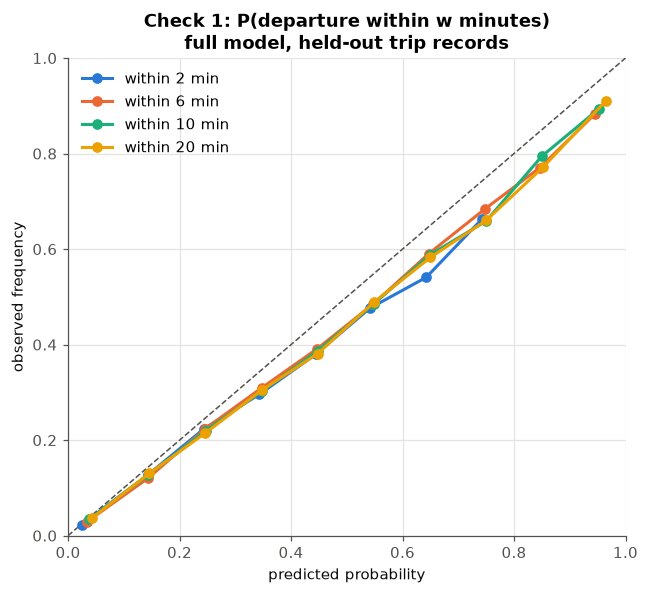

In [37]:
p_full = trip_predictions["3. Time of day + weather/season"]
fig, ax = plt.subplots(figsize=(6, 5.5))
plot_reliability(ax, [(f"within {w_min} min", p_full[q_w == w_min], q_observed[q_w == w_min]) for w_min in WINDOWS_MIN],
                 "Check 1: P(departure within w minutes)\nfull model, held-out trip records")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/check1_reliability_trips.png", dpi=150, bbox_inches="tight")
plt.show()

**Waiting-time check.** For the same random moments, measure the actual time $T$ until the next departure and convert it with the model: $u = 1 - e^{-\Lambda(t,\,t+T)}$. If the model's waiting-time distribution is right, $u$ is spread **evenly** between 0 and 1, so the histogram is flat. (This is called a *probability integral transform* check.)
- A pile-up near **0** means departures come *sooner* than the model expects (it underestimates the rate).
- A pile-up near **1** means they come *later* than expected. Some of this is expected here because of the empty-station caveat above.

When no departure happens within 2 hours, we only know $u$ is above a certain value, so a value is drawn at random above it (the standard way to handle this).

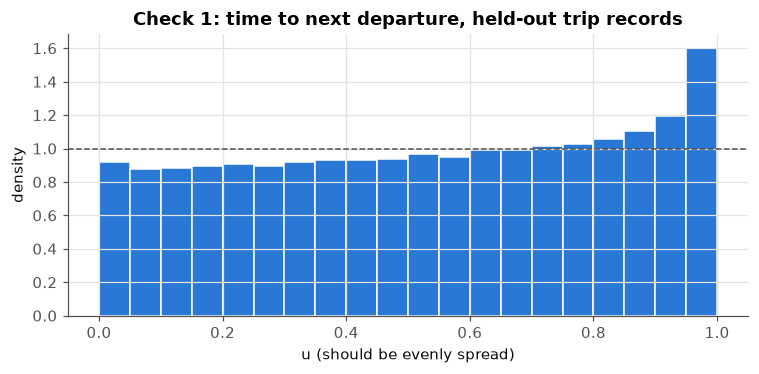

In [38]:
gap = minutes_to_next_departure(q_station, q_t, PIT_HORIZON_MIN)
seen = ~np.isnan(gap)
u = np.empty(len(gap))
u[seen] = 1 - np.exp(-expected_departures(q_station[seen], q_t[seen], gap[seen]))
u_floor = 1 - np.exp(-expected_departures(q_station[~seen], q_t[~seen], PIT_HORIZON_MIN))
u[~seen] = rng.uniform(u_floor, 1)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(u, bins=20, range=(0, 1), color=SERIES_COLORS[0], edgecolor="white", density=True)
ax.axhline(1, linestyle="--", color=INK_SECONDARY, linewidth=1)
ax.set_xlabel("u (should be evenly spread)"); ax.set_ylabel("density")
ax.set_title("Check 1: time to next departure, held-out trip records")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/check1_waiting_time_pit.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Load station status snapshots (for out-of-sample testing)

The status data records every station every 2 minutes: bikes, e-bikes, open docks, and whether the station was accepting returns. The first cell downloads the 2024 file if it isn't already at `STATUS_PATH`. The file is large (~584 million rows), so a **one-time cache** keeps only what's needed:
- days 15–end of each month (days 15–21 for recalibration, 22–end for testing; days 1–14 are never used);
- four columns: station name, time (converted to New York local time, in minutes since 2024-01-01), open docks, and whether the station was fully working (installed, renting and returning).

After that, each month is laid out as a grid: **stations × 2-minute snapshots**, with the number of open docks in each cell, or **−1 when there's no data** (station offline, not accepting returns, or a missed snapshot). A station is **full** when the cell is 0.

Stations are matched to the trip data **by name**. Both datasets come from the same Citi Bike system in the same year, so names line up. The match rate is printed below.

In [39]:
# Download only the 2024 file from Kaggle (4.2 GB), if it isn't here yet. Public dataset: no login needed.
# kagglehub saves into its own cache folder (~/.cache/kagglehub), so the file is then moved to STATUS_PATH.
if not os.path.exists(STATUS_PATH):
    import kagglehub
    import shutil
    downloaded = kagglehub.dataset_download("rosenthal/citi-bike-stations", path=os.path.basename(STATUS_PATH))
    os.makedirs(os.path.dirname(STATUS_PATH), exist_ok=True)
    shutil.move(downloaded, STATUS_PATH)
print(f"status file: {STATUS_PATH} ({os.path.getsize(STATUS_PATH) / 1e9:.1f} GB)")

status file: data/status/citi_bike_stations_2024.parquet (4.2 GB)


In [40]:
def build_status_cache(status_path, cache_dir, first_day):
    """One-time step (a few minutes): slim copy of the status file, one folder per month.
    If the cache folder already exists it is reused as-is. Delete it after changing STATUS_PATH or RECAL_FIRST_DAY."""
    if os.path.exists(cache_dir):
        print(f"reusing existing cache: {cache_dir} (delete it to rebuild)")
        return
    con = duckdb.connect()
    con.execute("SET TimeZone = 'UTC'")      # so timestamps are interpreted as UTC, as documented for this dataset
    con.execute(f"""
        COPY (
            SELECT station_name,
                   month(local_ts) AS month,
                   (epoch(local_ts) - epoch(TIMESTAMP '2024-01-01')) / 60.0 AS t_min,
                   num_docks_available::SMALLINT AS docks,
                   coalesce(is_installed::BOOLEAN AND is_renting::BOOLEAN AND is_returning::BOOLEAN, false) AS working
            FROM (SELECT *, timezone('America/New_York', fetched_at::TIMESTAMPTZ) AS local_ts
                  FROM read_parquet('{status_path}'))
            WHERE year(local_ts) = 2024
              AND day(local_ts) >= {first_day}
              AND num_docks_available IS NOT NULL
        ) TO '{cache_dir}' (FORMAT parquet, PARTITION_BY (month))
    """)
    con.close()
    print(f"cache written: {cache_dir}")


build_status_cache(STATUS_PATH, STATUS_CACHE_DIR, first_day=RECAL_FIRST_DAY)

reusing existing cache: data/status/status_2024_slim (delete it to rebuild)


In [41]:
con = duckdb.connect()
con.register("station_lookup", pd.DataFrame({"station_name": stations, "station": np.arange(n_stations)}))

status_names = con.execute(f"""
    SELECT station_name, count(*) AS snapshots
    FROM read_parquet('{STATUS_CACHE_DIR}/*/*.parquet') GROUP BY 1
""").df()
matched = status_names.station_name.isin(station_idx)
in_status = np.isin(stations, status_names.station_name)
print(f"status station names that match a trip station: {matched.mean():.1%} "
      f"({status_names.snapshots[matched].sum() / status_names.snapshots.sum():.1%} of snapshots)")
print(f"trip stations found in the status data: {in_status.mean():.1%} "
      f"({Y.sum(axis=0)[in_status].sum() / Y.sum():.1%} of 2024 departures)")

status station names that match a trip station: 98.9% (99.0% of snapshots)
trip stations found in the status data: 99.3% (100.0% of 2024 departures)


In [42]:
def load_status_block(con, month, first_day, last_day=None):
    """Grid of open docks for one month's day range: shape (n_stations, n_snapshots), -1 = no data.
    Column j is the snapshot at start_min + 2j minutes."""
    start = pd.Timestamp(2024, month, first_day)
    end = start + pd.offsets.MonthBegin(1) if last_day is None else pd.Timestamp(2024, month, last_day) + pd.Timedelta(days=1)
    start_min = (start - YEAR_START) / pd.Timedelta(minutes=1)
    end_min = (end - YEAR_START) / pd.Timedelta(minutes=1)
    n_polls = int(round((end_min - start_min) / STEP_MIN))
    docks = np.full((n_stations, n_polls), -1, dtype=np.int16)

    month_files = f"{STATUS_CACHE_DIR}/month={month}/*.parquet"
    if glob.glob(month_files):
        snap = con.execute(f"""
            SELECT l.station, s.t_min, s.docks, s.working
            FROM read_parquet('{month_files}') s JOIN station_lookup l USING (station_name)
            WHERE s.t_min >= ? AND s.t_min < ?
        """, [start_min, end_min]).df()
        poll = np.floor((snap.t_min.to_numpy() - start_min) / STEP_MIN).astype(np.int64)
        value = np.where(snap.working.to_numpy(), snap.docks.to_numpy(), -1)
        # If two snapshots fall in the same 2-minute slot (rare), one of them is kept.
        # Daylight-saving changes (Mar 10, Nov 3) fall outside the day ranges used here, so local times never repeat.
        docks[snap.station.to_numpy(), poll] = value

    # A single missed snapshot between two good ones is filled with the previous value.
    # (If a dock opened during the gap, it's counted at the next snapshot: at most 2 minutes late.)
    single_gap = (docks[:, 1:-1] == -1) & (docks[:, :-2] != -1) & (docks[:, 2:] != -1)
    docks[:, 1:-1][single_gap] = docks[:, :-2][single_gap]
    return {"month": month, "start_min": start_min, "docks": docks}


test_blocks = [load_status_block(con, m, TEST_FIRST_DAY) for m in MONTHS]
recal_blocks = [load_status_block(con, m, RECAL_FIRST_DAY, TRAIN_LAST_DAY) for m in MONTHS]

for name, blocks in [("test (days 22-end)", test_blocks), ("recalibration (days 15-21)", recal_blocks)]:
    known = sum((b["docks"] != -1).sum() for b in blocks)
    full = sum((b["docks"] == 0).sum() for b in blocks)
    print(f"{name}: {known:,} station-snapshots with data, {full / max(known, 1):.1%} of them full")

test (days 22-end): 177,191,405 station-snapshots with data, 6.7% of them full
recalibration (days 15-21): 130,908,509 station-snapshots with data, 6.8% of them full


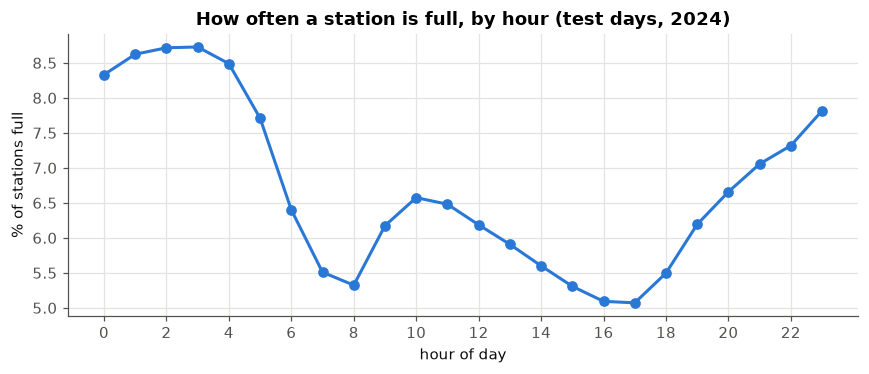

In [43]:
# Context: when are full stations most common? That's when the wait-or-ride-on decision matters most. (test days)
hour_known, hour_full = np.zeros(24), np.zeros(24)
for b in test_blocks:
    hours = ((b["start_min"] + STEP_MIN * np.arange(b["docks"].shape[1])) % 1440 // 60).astype(int)
    np.add.at(hour_known, hours, (b["docks"] != -1).sum(axis=0))
    np.add.at(hour_full, hours, (b["docks"] == 0).sum(axis=0))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(24), 100 * hour_full / np.maximum(hour_known, 1), marker="o", markersize=6, color=SERIES_COLORS[0])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day"); ax.set_ylabel("% of stations full")
ax.set_title("How often a station is full, by hour (test days, 2024)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/share_full_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Check 2 (out-of-sample): real full stations

Every snapshot where a station was full is a moment when a rider could have arrived and found no dock. For a sample of these moments on the **test days**, we measure from the snapshots how long it took until the station showed an open dock. Then we compare that with what the trip-based model predicted.

**Bookkeeping for each full-station moment:**
- `wait_min`: minutes until the first snapshot showing an open dock. Snapshots are 2 minutes apart, so this is exact to the 2-minute step.
- `full_through_min`: how long we *know* it stayed full. This matters when the data stops (station goes offline, a snapshot is missing, or the month's test period ends) before a dock opens. That moment is then only *partly* observed, which survival analysis calls *censoring*.
- `data_ok_min`: how many minutes of unbroken snapshots follow the moment, whatever they show.
- `elapsed_full_min`: how long the station had already been full when the rider arrived. The model in Section 4 assumes this doesn't matter. Section 8 tests that.

**Handling data gaps without bias.** It would be wrong to drop moments whenever we can't tell what happened. Moments that opened quickly would mostly survive while slow ones got cut off, which tilts results toward "a dock opened." So:
- the fixed-window checks (P(open within *w*)) keep a moment only if `data_ok_min ≥ w`. That's a rule about the data, not the outcome;
- the survival curves use partly observed moments directly (Kaplan–Meier).

This is the real test. These moments come from a **different data source** than the training data, on **days the model never saw**.

In [44]:
PERIOD_LABELS = ["Night 0-7h", "AM peak 7-10h", "Midday 10-16h", "PM peak 16-20h", "Evening 20-24h"]


def next_stop_index(docks):
    """For every (station, snapshot): the first snapshot at or after it where the station is NOT full
    (an open dock, or no data). Equals n_snapshots if it stays full to the end of the block."""
    n = docks.shape[1]
    idx = np.where(docks != 0, np.arange(n, dtype=np.int32), np.int32(n))
    return np.minimum.accumulate(idx[:, ::-1], axis=1)[:, ::-1]


def prev_stop_index(docks):
    """For every (station, snapshot): the last snapshot at or before it where the station was NOT full (-1 if none).
    No-data snapshots count as "not full" here, so `elapsed_full_min` restarts after a data gap (a lower bound)."""
    n = docks.shape[1]
    idx = np.where(docks != 0, np.arange(n, dtype=np.int32), np.int32(-1))
    return np.maximum.accumulate(idx, axis=1)


def next_missing_index(docks):
    """For every (station, snapshot): the first snapshot at or after it with no data. n_snapshots if there is none."""
    n = docks.shape[1]
    idx = np.where(docks == -1, np.arange(n, dtype=np.int32), np.int32(n))
    return np.minimum.accumulate(idx[:, ::-1], axis=1)[:, ::-1]


def full_station_events(blocks, max_per_block):
    """Sample of moments when a station was full, with what happened next."""
    frames = []
    for b, block in enumerate(blocks):
        docks = block["docks"]
        n = docks.shape[1]
        s, j = np.nonzero(docks == 0)
        if len(s) == 0:
            continue
        if len(s) > max_per_block:
            keep = rng.choice(len(s), max_per_block, replace=False)
            s, j = s[keep], j[keep]
        k = next_stop_index(docks)[s, j]          # first snapshot after j that is open or has no data
        opened = (k < n) & (docks[s, np.minimum(k, n - 1)] > 0)
        frames.append(pd.DataFrame({
            "block": b,
            "station": s,
            "poll": j,
            "t_min": block["start_min"] + STEP_MIN * j,
            "opened": opened,
            "wait_min": np.where(opened, STEP_MIN * (k - j), np.nan),
            "full_through_min": STEP_MIN * (k - j - 1),
            "data_ok_min": STEP_MIN * (next_missing_index(docks)[s, j] - j - 1),
            "elapsed_full_min": STEP_MIN * (j - prev_stop_index(docks)[s, j] - 1),
        }))
    events = pd.concat(frames, ignore_index=True)
    events["hour"] = (events.t_min % 1440 // 60).astype(int)
    events["period"] = pd.cut(events.hour, [-1, 6, 9, 15, 19, 23], labels=PERIOD_LABELS)
    return events


def outcome_within(events, w_min):
    """1 = a dock opened within w minutes, 0 = still full at w minutes,
    NaN = the snapshots have a gap inside the window (decided by data availability only, never by the outcome)."""
    complete = events.data_ok_min >= w_min
    opened_by_w = events.opened & (events.wait_min <= w_min)
    return np.where(complete, opened_by_w.astype(float), np.nan)


test_events = full_station_events(test_blocks, N_EVENTS_PER_BLOCK)
print(f"{len(test_events):,} full-station moments sampled from the test days")
print(f"dock opened before the data stopped: {test_events.opened.mean():.1%}")
test_events.head()

240,000 full-station moments sampled from the test days
dock opened before the data stopped: 96.8%


,block,station,poll,t_min,opened,wait_min,full_through_min,data_ok_min,elapsed_full_min,hour,period
0,0,18,5245,40730.0,True,226.0,224,3908,654,6,Night 0-7h
1,0,872,6576,43392.0,True,270.0,268,1246,364,3,Night 0-7h
2,0,107,5190,40620.0,True,430.0,428,4018,3462,5,Night 0-7h
3,0,497,711,31662.0,True,712.0,710,12976,304,23,Evening 20-24h
4,0,2134,6838,43916.0,True,10.0,8,722,22,11,Midday 10-16h


In [45]:
S_trip = survival_curves(test_events.station.to_numpy(), test_events.t_min.to_numpy())


def calibration_scores(events, survival, label):
    rows = []
    for w_min in WINDOWS_MIN:
        y = outcome_within(events, w_min)
        ok = ~np.isnan(y)
        p = 1 - survival[ok, w_min // STEP_MIN]
        rows.append({"model": label, "window (min)": w_min, "n": ok.sum(),
                     "avg predicted": p.mean(), "actually happened": y[ok].mean(), "Brier": brier(p, y[ok])})
    return pd.DataFrame(rows)


check2_scores = calibration_scores(test_events, S_trip, "trip-based")
check2_scores.round(3)

,model,window (min),n,avg predicted,actually happened,Brier
0,trip-based,2,239928,0.048,0.036,0.034
1,trip-based,6,239806,0.118,0.093,0.074
2,trip-based,10,239649,0.167,0.138,0.096
3,trip-based,20,239323,0.251,0.221,0.124


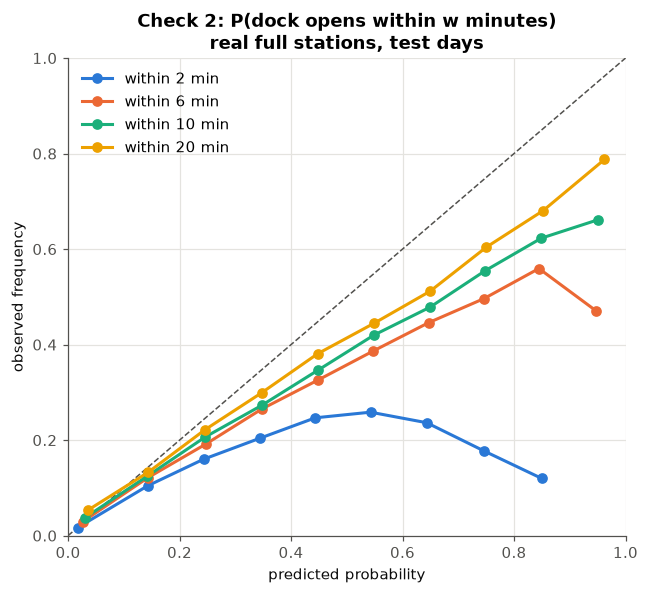

In [46]:
curves = []
for w_min in WINDOWS_MIN:
    y = outcome_within(test_events, w_min)
    ok = ~np.isnan(y)
    curves.append((f"within {w_min} min", 1 - S_trip[ok, w_min // STEP_MIN], y[ok]))

fig, ax = plt.subplots(figsize=(6, 5.5))
plot_reliability(ax, curves, "Check 2: P(dock opens within w minutes)\nreal full stations, test days")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/check2_reliability_status.png", dpi=150, bbox_inches="tight")
plt.show()

**Survival curves.** The dark line is what actually happened: the share of full-station moments still full after *u* minutes. It's estimated with the *Kaplan–Meier* method, which uses partly observed moments correctly. The colored line is the model's prediction for the same moments. If the colored line sits **below** the dark one, the model is too optimistic: docks open more slowly than trip departures suggest. If it sits **above**, docks open faster than trips alone explain (for example, rebalancing trucks removing bikes).

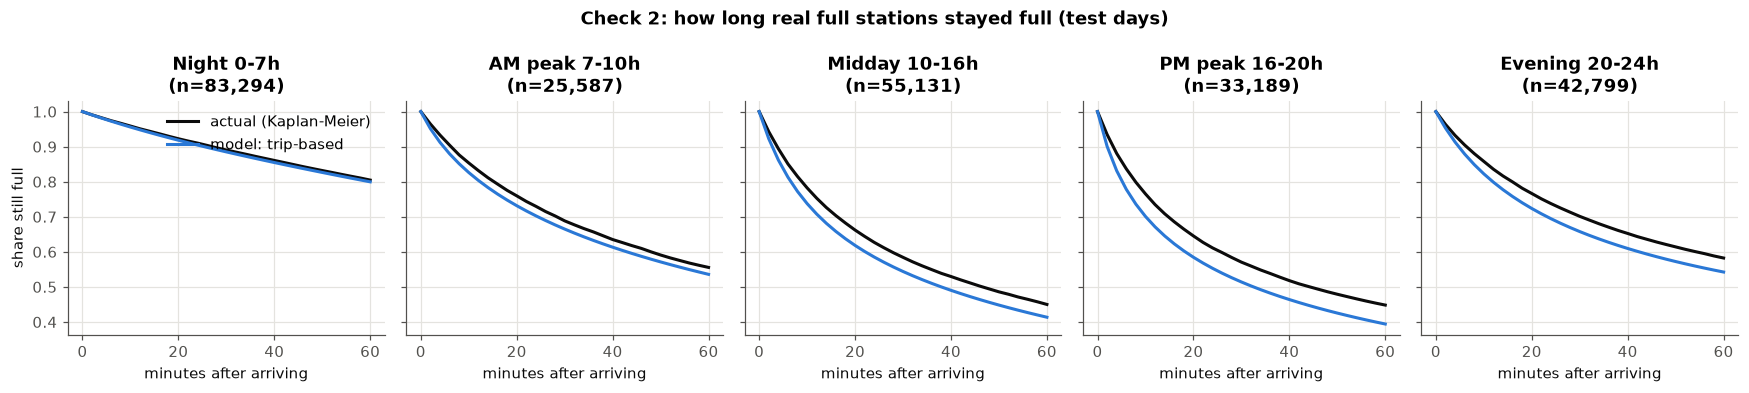

In [47]:
def kaplan_meier(events, max_min=MAX_WAIT_MIN):
    """Share of full-station moments still full after u minutes (u = 0, 2, ..., max_min), allowing for data gaps."""
    times = np.arange(0, max_min + STEP_MIN, STEP_MIN)
    opened = events.opened.to_numpy()
    open_time = events.wait_min.to_numpy()[opened]
    known_full_until = events.full_through_min.to_numpy()[~opened]
    still_full = [1.0]
    for u in times[1:]:
        at_risk = (open_time >= u).sum() + (known_full_until >= u).sum()
        opened_now = (open_time == u).sum()
        still_full.append(still_full[-1] * (1 - opened_now / at_risk) if at_risk > 0 else still_full[-1])
    return times, np.array(still_full)


def plot_survival_by_period(events, model_curves, title, filename):
    """model_curves: list of (label, survival array aligned with events)."""
    fig, axes = plt.subplots(1, len(PERIOD_LABELS), figsize=(16, 3.6), sharey=True)
    minutes = np.arange(0, MAX_WAIT_MIN + STEP_MIN, STEP_MIN)
    for ax, period in zip(axes, PERIOD_LABELS):
        in_period = (events.period == period).to_numpy()
        if in_period.sum() == 0:
            ax.set_title(f"{period}\n(no data)")
            continue
        times, km = kaplan_meier(events[in_period])
        ax.plot(times, km, color=INK, label="actual (Kaplan-Meier)")
        for color, (label, S) in zip(SERIES_COLORS, model_curves):
            ax.plot(minutes, S[in_period].mean(axis=0), color=color, label=label)
        ax.set_title(f"{period}\n(n={in_period.sum():,})")
        ax.set_xlabel("minutes after arriving")
    axes[0].set_ylabel("share still full")
    axes[0].legend(loc="upper right")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{filename}", dpi=150, bbox_inches="tight")
    plt.show()


plot_survival_by_period(test_events, [("model: trip-based", S_trip)],
                        "Check 2: how long real full stations stayed full (test days)", "check2_survival_trip_model.png")

**What can make reality differ from the trip-based model**
- **Other riders compete for the freed dock.** When a bike leaves, someone else arriving may take that dock first, so the station stays full. This makes reality *slower* than the model.
- **Rebalancing.** Trucks and valets remove bikes from full stations. Those removals aren't in trip records, so this makes reality *faster* than the model.
- **Very short openings are missed.** A dock that opens and is refilled within 2 minutes never shows up in a snapshot. This makes reality look *slower*.
- **"Full" stations that don't recover.** A station showing 0 open docks because of broken docks may not behave like a normal full station.

Section 8 measures the net effect of all of these and corrects for it.

## 8. Recalibration (optional): learn what trip data misses

A small correction, fitted on status snapshots from **days 15–21** (inside the training period, never the test days). For each full-station snapshot we ask: did a dock open by the next snapshot, 2 minutes later? The model for that probability is

$$P(\text{dock opens in next 2 min}) = 1 - \exp\!\big(-e^{a}\,\Lambda_2^{\,b}\,(1+\text{minutes the station has been full})^{c}\big)$$

where $\Lambda_2$ is the trip model's expected departures in those 2 minutes. (In the code, a tiny `LAM_FLOOR` is added to $\Lambda_2$ so stations with almost no predicted demand don't produce log(0).) This is a *complementary log-log* regression with three numbers to fit:
- $a = 0,\ b = 1,\ c = 0$ gives back **exactly the trip-based model**, so the fitted values directly measure what trips get wrong;
- $e^{a}$ is the overall scaling: below 1 means docks open more slowly than departures suggest (competition), above 1 means faster (rebalancing);
- $b$ shows how closely real dock openings follow the trip-predicted rate (1 = proportionally);
- $c$ tests whether it matters how long the station had already been full when you arrived. The trip model assumes it doesn't. Negative means stations that have been full for a while tend to stay full.

In [48]:
def fit_recalibration(lam, elapsed, opened_next):
    """Maximum-likelihood fit of (a, b, c) in the complementary log-log model above."""
    features = np.column_stack([np.ones_like(lam), np.log(lam + LAM_FLOOR), np.log1p(elapsed)])

    def negative_log_likelihood(params):
        hazard = np.exp(np.clip(features @ params, -30, 5))
        log_p_open = np.log(-np.expm1(-hazard) + 1e-12)       # log(1 - exp(-hazard))
        log_p_stay = -hazard
        return -np.mean(opened_next * log_p_open + (1 - opened_next) * log_p_stay)

    result = minimize(negative_log_likelihood, x0=np.array([0.0, 1.0, 0.0]), method="L-BFGS-B")
    return result.x


recal_events = full_station_events(recal_blocks, N_EVENTS_PER_BLOCK)
r = recal_events[recal_events.data_ok_min >= STEP_MIN]        # keep snapshots whose next snapshot has data (whatever it shows)
opened_next = (r.opened & (r.wait_min == STEP_MIN)).to_numpy().astype(float)
lam_2min = expected_departures(r.station.to_numpy(), r.t_min.to_numpy(), STEP_MIN)

recal_params = fit_recalibration(lam_2min, r.elapsed_full_min.to_numpy(), opened_next)
a, b, c = recal_params
print(f"fitted on {len(r):,} full-station snapshots (days 15-21)")
print(f"a = {a:+.2f}   b = {b:.2f}   c = {c:+.2f}     (a=0, b=1, c=0 would mean the trip model needs no correction)")
for lam in [0.05, 0.2, 0.5]:
    ratio = np.exp(a) * (lam + LAM_FLOOR) ** b / lam
    print(f"  where trips predict {lam} departures per 2 min, docks actually open at {ratio:.2f}x that rate (just-filled station)")
ELAPSED_EXAMPLE_MIN = 30
print(f"  after {ELAPSED_EXAMPLE_MIN} minutes already full, the opening rate is "
      f"{(1 + ELAPSED_EXAMPLE_MIN) ** c:.2f}x the rate of a station that just filled")

fitted on 239,910 full-station snapshots (days 15-21)
a = -0.50   b = 0.64   c = -0.21     (a=0, b=1, c=0 would mean the trip model needs no correction)
  where trips predict 0.05 departures per 2 min, docks actually open at 1.81x that rate (just-filled station)
  where trips predict 0.2 departures per 2 min, docks actually open at 1.09x that rate (just-filled station)
  where trips predict 0.5 departures per 2 min, docks actually open at 0.78x that rate (just-filled station)
  after 30 minutes already full, the opening rate is 0.49x the rate of a station that just filled


In [49]:
S_recal = survival_curves(test_events.station.to_numpy(), test_events.t_min.to_numpy(),
                          test_events.elapsed_full_min.to_numpy(), recal=recal_params)
check2_both = pd.concat([check2_scores, calibration_scores(test_events, S_recal, "recalibrated")])
print("Out-of-sample on test days:")
check2_both.pivot(index="model", columns="window (min)", values=["Brier", "avg predicted", "actually happened"]).round(3)

Out-of-sample on test days:


Brier                      avg predicted                       \
window (min)     2      6      10     20            2      6      10     20   
model                                                                         
recalibrated  0.032  0.068  0.088  0.115         0.038  0.096  0.142  0.229   
trip-based    0.034  0.074  0.096  0.124         0.048  0.118  0.167  0.251   

             actually happened                       
window (min)                2      6      10     20  
model                                                
recalibrated             0.036  0.093  0.138  0.221  
trip-based               0.036  0.093  0.138  0.221

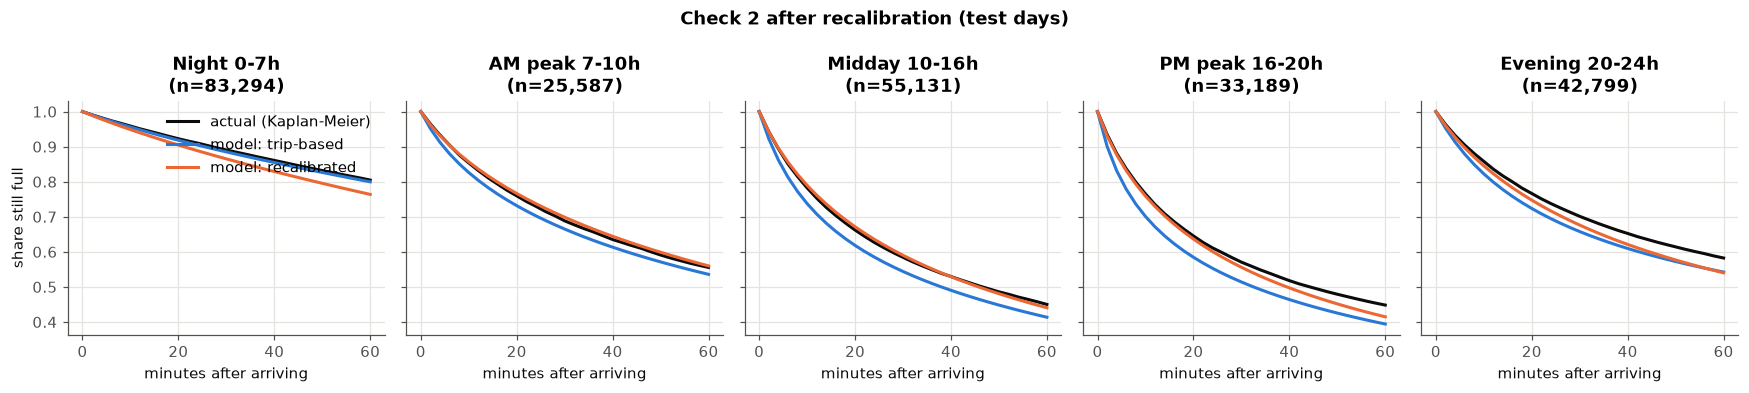

In [50]:
plot_survival_by_period(test_events, [("model: trip-based", S_trip), ("model: recalibrated", S_recal)],
                        "Check 2 after recalibration (test days)", "check2_survival_recalibrated.png")

## 9. The decision model, replayed on real full stations

**The rule.** At a full station, consider staying and the nearest other stations (up to `NEIGHBOR_K = 5` within `NEIGHBOR_RADIUS_M = 500 m`). For each option:

$$\text{expected total time} = \underbrace{\text{ride there}}_{\text{0 if staying}} + \underbrace{\text{expected wait for a dock}}_{\text{from the survival curve}} + \underbrace{\text{walk back to where you were going}}_{\text{0 if staying}}$$

Recommend the option with the smallest expected total. Distances are straight-line × 1.3 for the street grid, riding at 200 m/min and walking at 80 m/min.

**Why "K nearest within a radius".** Pure K-nearest would give outer-borough stations "neighbors" over a kilometer away, which are never worth it. A pure radius would give some Midtown stations more than 15 options. Capping both keeps the choice small and realistic.

**Decision rules compared**, all replayed on the same real full-station moments from the test days:

| Rule | Uses live data? | Description |
|---|---|---|
| Always wait | no | stay at the full station |
| Always ride to nearest | no | ride to the nearest other station, wait there if needed |
| Nearest showing open docks | **yes** | what a rider does with the app today; if none nearby, wait |
| Model (trip-based) | no | rule above; another station's expected wait = P(it's also full, measured in the training weeks) × its expected wait if full |
| Model (trip-based) + live | **yes** | rule above; stations showing open docks right now count as no wait |
| Model (recalibrated), ± live | as above | same, using the Section 8 correction (it also needs how long a station has been full; other stations, if full, are treated as just filled) |
| Hindsight best | uses the future | the option that actually turned out fastest: the best any rule could possibly do |

**How a choice is scored.** We look at the snapshot when the rider would have arrived at the chosen station. If it shows an open dock, the wait is 0. Otherwise the wait is the time until it shows one. Total = ride + actual wait + walk back. A station that isn't working at the moment of deciding (offline or not accepting returns) is not offered as an option. A moment is kept only if every option has unbroken snapshots for `MAX_WAIT_MIN` after arrival. That rule depends on the data only, never on outcomes, so all rules are compared on exactly the same moments without bias.

**The summary counts riders, not moments.** Each moment is weighted by how many riders typically arrive at that station at that time (Section 9b). The unweighted version is shown after it.

**Columns in the summary table:**
- *mean / median / 90th pct*: minutes from arriving at the full station until the bike is docked and the rider is back at their destination. The 90th percentile is the bad-case outcome: 1 in 10 moments is worse than this.
- *% over `LONG_WAIT_MIN`*: share of moments where that total exceeded 15 minutes.
- *% rode on*: how often the rule chose to leave the full station.
- *mean minutes lost vs hindsight*: average gap between the rule and the best possible choice (0 = perfect).

In [51]:
EARTH_RADIUS_M = 6_371_000

coords = station_coords.reindex(stations)[["lat", "lon"]].to_numpy()
has_coords = np.isfinite(coords).all(axis=1)
has_status = np.zeros(n_stations, dtype=bool)
for block in test_blocks:
    has_status |= (block["docks"] != -1).any(axis=1)
candidates = np.flatnonzero(has_coords & has_status)      # stations a rider could be sent to

tree = BallTree(np.radians(coords[candidates]), metric="haversine")
query = np.flatnonzero(has_coords)
dist, ind = tree.query(np.radians(coords[query]), k=min(NEIGHBOR_K + 1, len(candidates)))
dist_m, neighbor_ids = dist * EARTH_RADIUS_M, candidates[ind]

neighbors = np.full((n_stations, NEIGHBOR_K), -1)               # -1 = no neighbor in that slot
neighbor_dist_m = np.full((n_stations, NEIGHBOR_K), np.nan)
for row, s in enumerate(query):
    keep = np.flatnonzero((neighbor_ids[row] != s) & (dist_m[row] <= NEIGHBOR_RADIUS_M))[:NEIGHBOR_K]
    neighbors[s, :len(keep)] = neighbor_ids[row, keep]
    neighbor_dist_m[s, :len(keep)] = dist_m[row, keep]

n_neighbors = (neighbors[has_status] >= 0).sum(axis=1)
print("number of neighbors within the radius (stations with status data):")
print(pd.Series(n_neighbors).value_counts().sort_index().rename("stations").to_string())

number of neighbors within the radius (stations with status data):
0      12
1      17
2      30
3      50
4     104
5    2040


### 9a. Without live data: how likely is a nearby station to be full too?
Without live data, the rider doesn't know whether the nearby stations are full. Assuming they all are turned out far too pessimistic: that version of the model stayed put much more often than the best choice did. Instead, we measure it from the snapshots in the recalibration weeks (days 15–21, never the test days). **Of all the moments a station was full, how often was each of its neighbors also full?** This captures the fact that nearby stations tend to fill up together (for example, a residential area overnight). Pairs with little data are pulled toward the neighbor's overall share of time full (`NEIGHBOR_PRIOR_SNAPSHOTS`).

In [52]:
def neighbor_full_rates(blocks, neighbors, prior_snapshots=NEIGHBOR_PRIOR_SNAPSHOTS):
    """P(neighbor is full | this station is full) for every station and each of its neighbors, shape (n_stations, K).
    Measured on the recalibration-week snapshots and shrunk toward the neighbor's overall share of time full,
    as if `prior_snapshots` extra snapshots had been seen at that share. Also returns each station's share of time full."""
    k_max = neighbors.shape[1]
    safe = np.maximum(neighbors, 0)                          # placeholder index for empty neighbor slots (masked at the end)
    station_full_neighbor_known = np.zeros((n_stations, k_max))
    both_full = np.zeros((n_stations, k_max))
    full_count, known_count = np.zeros(n_stations), np.zeros(n_stations)
    for block in blocks:
        full, known = block["docks"] == 0, block["docks"] != -1
        full_count += full.sum(axis=1)
        known_count += known.sum(axis=1)
        for k in range(k_max):
            station_full_neighbor_known[:, k] += (full & known[safe[:, k]]).sum(axis=1)
            both_full[:, k] += (full & full[safe[:, k]]).sum(axis=1)
    share_full = np.divide(full_count, known_count, out=np.zeros(n_stations), where=known_count > 0)
    rate = (both_full + prior_snapshots * share_full[safe]) / (station_full_neighbor_known + prior_snapshots)
    return np.where(neighbors >= 0, rate, np.nan), share_full


neighbor_full_given_full, share_full = neighbor_full_rates(recal_blocks, neighbors)
nearest = neighbors[:, 0]
has_nearest = has_status & (nearest >= 0)
print(f"when a station is full, its nearest neighbor is also full {np.mean(neighbor_full_given_full[has_nearest, 0]):.1%} of the time")
print(f"at a random moment, those same neighbors are full {np.mean(share_full[nearest[has_nearest]]):.1%} of the time")


when a station is full, its nearest neighbor is also full 21.0% of the time
at a random moment, those same neighbors are full 6.8% of the time


### 9b. Counting riders, not moments
Full-station moments are sampled evenly over time. So a station that's full all night contributes as many moments as one that's full during the evening rush, even though almost no one shows up to return a bike at 3am. To measure what riders actually experience, each moment is **weighted by how many riders typically arrive to return a bike at that station at that time**. That's the station's average arrivals for that half-hour and day type on the training days (from `df_enter_final`, fitted with the same function as the departure model), adjusted by the weather/season multiplier.

Caveat: trip records undercount arrivals at stations that are often full, because riders who find a station full end their trip somewhere else. So those stations get somewhat less weight than their true demand.

In [53]:
# Arrivals per station per 30-minute slot (from Section 2's df_enter_final), aligned with the departure arrays
arrivals = (df_enter_final[df_enter_final.index.year == 2024]
            .reindex(index=dates, columns=stations, fill_value=0)
            .to_numpy(dtype=np.float32))
arrival_base = fit_base_rates(arrivals, active, is_train, profile_key, multiplier)   # same estimator as the departure model


def expected_arrivals_per_min(station, t_min):
    """Riders expected to arrive to return a bike at `station`, per minute, around t_min
    (training-day average for that time slot, times the weather/season multiplier)."""
    slot = np.clip(np.asarray(t_min) // 30, 0, n_slots - 1).astype(np.int64)
    return arrival_base[profile_key[slot], station] * multiplier[slot] / 30


In [54]:
POLICIES = [
    "Always wait",
    "Always ride to nearest",
    "Nearest showing open docks (app today)",
    "Model: trip-based",
    "Model: trip-based + live",
    "Model: recalibrated",
    "Model: recalibrated + live",
    "Hindsight best",
]


def actual_wait(docks, next_stop, next_missing, station, arrival_poll):
    """What really happened to a rider reaching `station` at snapshot `arrival_poll`.
    Returns (wait in minutes, capped at MAX_WAIT_MIN; known = unbroken snapshots for MAX_WAIT_MIN after arrival)."""
    n = docks.shape[1]
    poll = np.minimum(arrival_poll, n - 1)
    st = np.maximum(station, 0)                      # placeholder index for empty neighbor slots (masked below)
    k = next_stop[st, poll]                          # first snapshot from arrival on that is open or has no data
    opens = (k < n) & (docks[st, np.minimum(k, n - 1)] > 0)
    unbroken = next_missing[st, poll] - arrival_poll > MAX_WAIT_MIN // STEP_MIN
    known = (station >= 0) & (arrival_poll < n) & unbroken
    wait = np.where(opens, STEP_MIN * (k - poll), MAX_WAIT_MIN)
    return np.minimum(wait, MAX_WAIT_MIN), known


def replay_block(block, events):
    """Run every decision rule on a set of full-station moments from one month's test days."""
    docks = block["docks"]
    next_stop, next_missing = next_stop_index(docks), next_missing_index(docks)
    s0, poll, t0 = events.station.to_numpy(), events.poll.to_numpy(), events.t_min.to_numpy()
    n = len(s0)

    # Options: column 0 = stay; columns 1..K = nearest other stations (in distance order).
    # A station that isn't working at the moment of deciding (no data) can't be chosen.
    options = np.column_stack([s0, neighbors[s0]])
    working_now = docks[np.maximum(options, 0), poll[:, None]] != -1
    options = np.where(working_now, options, -1)
    valid = options >= 0
    dist = np.column_stack([np.zeros(n), neighbor_dist_m[s0]])
    ride_min = np.nan_to_num(dist * DETOUR_FACTOR / BIKE_SPEED_M_MIN)
    walk_min = np.nan_to_num(dist * DETOUR_FACTOR / WALK_SPEED_M_MIN)
    travel_min = ride_min + walk_min

    # What actually happened (from the snapshots)
    arrival_poll = poll[:, None] + np.ceil(ride_min / STEP_MIN).astype(int)
    real_wait, known = actual_wait(docks, next_stop, next_missing, options, arrival_poll)
    real_total = np.where(valid, travel_min + real_wait, np.inf)
    all_known = (known | ~valid).all(axis=1)

    # What the rider would see in the app at the moment of deciding
    open_now = valid & (docks[np.maximum(options, 0), poll[:, None]] > 0)

    # What each model expects (uses only information available at the moment of deciding)
    arrive_t = t0[:, None] + ride_min
    elapsed = np.column_stack([events.elapsed_full_min.to_numpy(), np.zeros((n, NEIGHBOR_K))])  # others: assume just filled
    # Without live data: the station you're at is known to be full; another station is full with the
    # probability measured in the training weeks when this station was full (Section 9a).
    p_full = np.column_stack([np.ones(n), np.nan_to_num(neighbor_full_given_full[s0])])
    expected_cost = {}
    for name, params in [("trip-based", None), ("recalibrated", recal_params)]:
        S = survival_curves(np.maximum(options, 0).ravel(), arrive_t.ravel(), elapsed.ravel(), recal=params)
        wait = expected_wait(S).reshape(options.shape)                 # expected wait IF the station is full
        expected_cost[name] = np.where(valid, travel_min + p_full * wait, np.inf)
        expected_cost[name + " + live"] = np.where(valid, travel_min + np.where(open_now, 0, wait), np.inf)

    has_open = open_now[:, 1:].any(axis=1)
    choice = {
        "Always wait": np.zeros(n, dtype=int),
        "Always ride to nearest": np.where(valid[:, 1], 1, 0),
        "Nearest showing open docks (app today)": np.where(has_open, 1 + open_now[:, 1:].argmax(axis=1), 0),
        "Model: trip-based": expected_cost["trip-based"].argmin(axis=1),
        "Model: trip-based + live": expected_cost["trip-based + live"].argmin(axis=1),
        "Model: recalibrated": expected_cost["recalibrated"].argmin(axis=1),
        "Model: recalibrated + live": expected_cost["recalibrated + live"].argmin(axis=1),
        "Hindsight best": real_total.argmin(axis=1),
    }
    rows = np.arange(n)
    result = events[["station", "t_min", "period"]].reset_index(drop=True)
    result["rider_weight"] = expected_arrivals_per_min(s0, t0)          # how many riders this moment represents (9b)
    for policy in POLICIES:
        result[policy] = real_total[rows, choice[policy]]
        result["moved: " + policy] = choice[policy] > 0
    detail = {"options": options, "dist": dist, "ride_min": ride_min, "walk_min": walk_min, "real_wait": real_wait,
              "expected_trip_live": expected_cost["trip-based + live"], "open_now": open_now}
    return result[all_known], {k: v[all_known] for k, v in detail.items()}

In [55]:
replay_parts, replay_details = [], []
for block_number, block in enumerate(test_blocks):   # not `b`: that name holds a recalibration parameter
    month_events = test_events[test_events.block == block_number]
    if len(month_events) == 0:
        continue
    month_events = month_events.sample(min(N_REPLAY_PER_BLOCK, len(month_events)), random_state=SEED)
    result, detail = replay_block(block, month_events)
    replay_parts.append(result)
    replay_details.append(detail)

replay = pd.concat(replay_parts, ignore_index=True)
n_sampled = sum(min(N_REPLAY_PER_BLOCK, (test_events.block == block_number).sum()) for block_number in range(len(test_blocks)))
print(f"{len(replay):,} of {n_sampled:,} sampled full-station moments kept "
      f"(the rest had a data gap within {MAX_WAIT_MIN} minutes at one of the options)")


def weighted_quantile(values, weights, q):
    """The value below which a share q of the total weight falls."""
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][min(np.searchsorted(cumulative, q), len(values) - 1)]


def summarize(replay, weights):
    """One row per decision rule. `weights` = how much each moment counts (all ones = every moment counts the same)."""
    w = np.asarray(weights, dtype=float)
    best = replay["Hindsight best"].to_numpy()
    rows = []
    for policy in POLICIES:
        total = replay[policy].to_numpy()
        rows.append({
            "rule": policy,
            "mean total (min)": np.average(total, weights=w),
            "median (min)": weighted_quantile(total, w, 0.5),
            "90th pct (min)": weighted_quantile(total, w, 0.9),
            f"% over {LONG_WAIT_MIN} min": 100 * np.average(total > LONG_WAIT_MIN, weights=w),
            "% rode on": 100 * np.average(replay["moved: " + policy].to_numpy(), weights=w),
            "mean minutes lost vs hindsight": np.average(total - best, weights=w),
        })
    return pd.DataFrame(rows).set_index("rule").round(2)


decision_summary = summarize(replay, replay.rider_weight)                  # main result: per rider
decision_summary_by_moment = summarize(replay, np.ones(len(replay)))       # every full-station moment counts the same
print("Per rider (each moment weighted by how many riders typically arrive then):")
decision_summary

59,038 of 60,000 sampled full-station moments kept (the rest had a data gap within 60 minutes at one of the options)
Per rider (each moment weighted by how many riders typically arrive then):


,mean total (min),median (min),90th pct (min),% over 15 min,% rode on,mean minutes lost vs hindsight
rule,,,,,,
Always wait,23.98,14.00,60.00,48.50,0.00,19.18
Always ride to nearest,12.59,5.19,41.74,19.71,92.11,7.79
Nearest showing open docks (app today),6.56,5.00,8.06,4.64,96.74,1.77
Model: trip-based,11.59,6.00,28.78,17.41,69.33,6.79
Model: trip-based + live,7.98,4.93,12.86,8.93,77.39,3.18
Model: recalibrated,9.91,5.83,19.74,12.52,91.38,5.11
Model: recalibrated + live,6.53,4.96,8.25,4.83,94.27,1.74
Hindsight best,4.80,4.27,6.73,1.00,77.68,0.00


In [56]:
print("Per full-station moment (unweighted), for comparison:")
decision_summary_by_moment

Per full-station moment (unweighted), for comparison:


,mean total (min),median (min),90th pct (min),% over 15 min,% rode on,mean minutes lost vs hindsight
rule,,,,,,
Always wait,45.10,60.00,60.00,82.66,0.00,38.44
Always ride to nearest,20.51,5.67,64.69,30.37,94.43,13.85
Nearest showing open docks (app today),7.68,5.37,8.53,4.90,95.73,1.02
Model: trip-based,15.16,7.24,63.71,17.65,95.60,8.51
Model: trip-based + live,7.78,5.37,8.74,5.29,94.71,1.13
Model: recalibrated,14.94,7.13,63.82,17.01,98.64,8.28
Model: recalibrated + live,7.65,5.37,8.56,4.84,97.43,0.99
Hindsight best,6.66,5.21,8.00,3.23,91.11,0.00


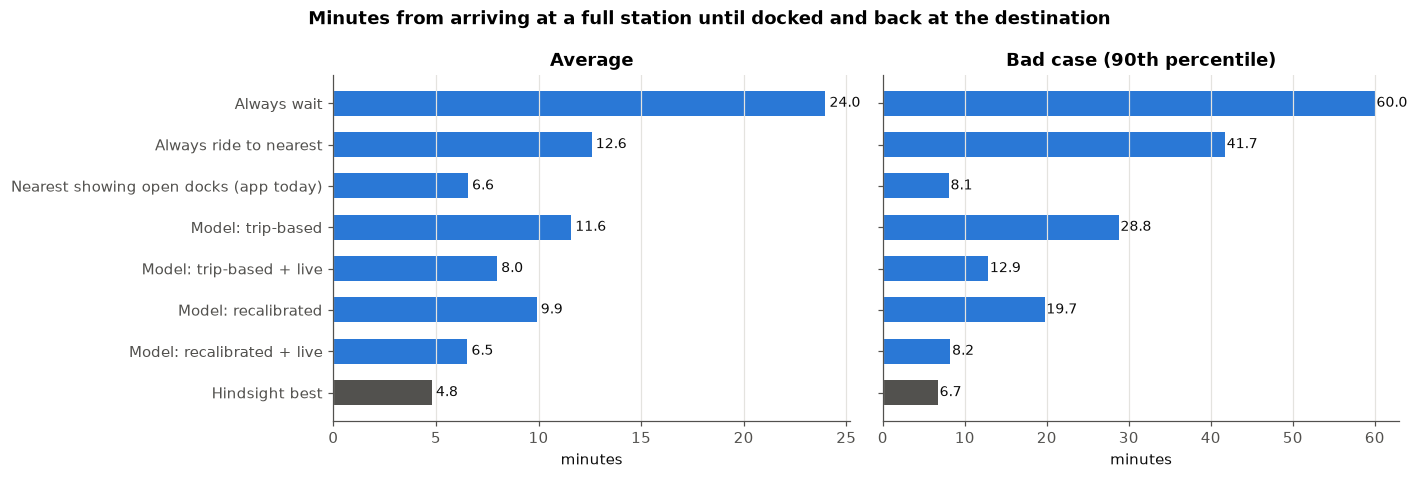

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
order = decision_summary.index[::-1]
for ax, (metric, title) in zip(axes, [("mean total (min)", "Average"), ("90th pct (min)", "Bad case (90th percentile)")]):
    values = decision_summary.loc[order, metric]
    colors = [INK_SECONDARY if rule == "Hindsight best" else SERIES_COLORS[0] for rule in order]
    ax.barh(order, values, color=colors, height=0.6)
    for y_pos, value in enumerate(values):
        ax.text(value + 0.2, y_pos, f"{value:.1f}", va="center", color=INK, fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("minutes")
    ax.grid(axis="y", visible=False)
fig.suptitle("Minutes from arriving at a full station until docked and back at the destination", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/decision_rules_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [58]:
# Does the best rule depend on the time of day? Rider-weighted mean total minutes per rule (rows) and period (columns)
rider_w = replay.rider_weight
period_weight = rider_w.groupby(replay.period, observed=True).sum()
by_period = replay[POLICIES].mul(rider_w, axis=0).groupby(replay.period, observed=True).sum().div(period_weight, axis=0)
print("share of riders in each period: " + ", ".join(f"{p} {s:.0%}" for p, s in (period_weight / period_weight.sum()).items()))
by_period.T.round(1)

share of riders in each period: Night 0-7h 6%, AM peak 7-10h 14%, Midday 10-16h 35%, PM peak 16-20h 28%, Evening 20-24h 17%


period,Night 0-7h,AM peak 7-10h,Midday 10-16h,PM peak 16-20h,Evening 20-24h
Always wait,43.3,26.9,20.7,19.7,27.9
Always ride to nearest,21.3,12.8,11.7,10.5,14.3
Nearest showing open docks (app today),7.5,6.6,6.5,6.1,7.0
Model: trip-based,14.2,12.1,10.9,11.7,11.5
Model: trip-based + live,7.4,8.9,7.7,8.6,7.0
Model: recalibrated,14.1,10.2,9.3,8.9,11.0
Model: recalibrated + live,7.4,6.7,6.5,6.1,6.9
Hindsight best,6.3,5.0,4.6,4.4,5.1


**One decision, worked through.** A single replayed moment where the model (trip-based + live) recommended riding on, showing what it saw and what really happened.

In [59]:
detail = {k: np.concatenate([d[k] for d in replay_details]) for k in replay_details[0]}
moved = np.flatnonzero(replay["moved: Model: trip-based + live"].to_numpy() & ((detail["options"] >= 0).sum(axis=1) >= 3))
if len(moved) == 0:
    print("no replayed moment where the model chose to ride on")
else:
    i = moved[0]
    when = YEAR_START + pd.Timedelta(minutes=float(replay.t_min.iloc[i]))
    print(f"Full station: {stations[replay.station.iloc[i]]}   at {when:%a %b %d %H:%M}")
    valid_opts = detail["options"][i] >= 0
    example = pd.DataFrame({
        "option": ["stay (full)"] + [f"ride to {stations[s]}" for s in detail["options"][i][1:][valid_opts[1:]]],
        "distance (m)": detail["dist"][i][valid_opts].round(0),
        "shows open dock now": detail["open_now"][i][valid_opts],
        "ride + walk (min)": (detail["ride_min"][i] + detail["walk_min"][i])[valid_opts].round(1),
        "model: expected total (min)": detail["expected_trip_live"][i][valid_opts].round(1),
        "actual total (min)": (detail["ride_min"][i] + detail["walk_min"][i] + detail["real_wait"][i])[valid_opts].round(1),
    })
    display(example)

Full station: 60 Pl & Flushing Ave   at Mon Jan 29 13:58


,option,distance (m),shows open dock now,ride + walk (min),model: expected total (min),actual total (min)
0,stay (full),0.0,False,0.0,57.7,60.0
1,ride to Grand Ave & 58 Ave,173.0,False,3.9,60.8,25.9
2,ride to Fresh Pond Rd & Flushing Ave,288.0,False,6.5,61.8,66.5
3,ride to 59 St & 59 Rd,328.0,True,7.5,7.5,7.5
4,ride to 57 Rd & 59 St,384.0,True,8.7,8.7,8.7
5,ride to 63 St & 59 Dr,400.0,True,9.1,9.1,9.1


## 10. Summary

In [60]:
check1_10 = trip_scores[trip_scores["window (min)"] == 10].set_index("model")
check2_10 = check2_both[check2_both["window (min)"] == 10].set_index("model")
best_rule = decision_summary.drop(index="Hindsight best")["mean total (min)"].idxmin()

print("Check 1, held-out trips, 10-minute window (Brier, lower is better):")
for model, row in check1_10.iterrows():
    print(f"  {model:<32} {row['Brier']:.4f}")
print("Check 2, real full stations, 10-minute window:")
for model, row in check2_10.iterrows():
    print(f"  {model:<14} predicted {row['avg predicted']:.1%} opened, actually {row['actually happened']:.1%}  (Brier {row['Brier']:.3f})")
print(f"Recalibration: a = {a:+.2f}, b = {b:.2f}, c = {c:+.2f}")
print(f"Decision replay, {len(replay):,} real full-station moments, mean minutes until done (per rider):")
for rule in dict.fromkeys(["Always wait", "Nearest showing open docks (app today)", best_rule, "Hindsight best"]):   # no repeats
    print(f"  {rule:<40} {decision_summary.loc[rule, 'mean total (min)']:.1f}")

Check 1, held-out trips, 10-minute window (Brier, lower is better):
  1. Station average               0.1447
  2. Time of day                   0.1149
  3. Time of day + weather/season  0.1084
Check 2, real full stations, 10-minute window:
  trip-based     predicted 16.7% opened, actually 13.8%  (Brier 0.096)
  recalibrated   predicted 14.2% opened, actually 13.8%  (Brier 0.088)
Recalibration: a = -0.50, b = 0.64, c = -0.21
Decision replay, 59,038 real full-station moments, mean minutes until done (per rider):
  Always wait                              24.0
  Nearest showing open docks (app today)   6.6
  Model: recalibrated + live               6.5
  Hindsight best                           4.8


### Results in words
Numbers are from the run saved in this notebook (full 2024 data, `SEED = 42`).

**1. Are the probabilities right?** Nearly, and the three-number correction closes most of the gap. On held-out trips, each model ingredient improves the 10-minute Brier score (0.145 → 0.115 → 0.108). At real full stations (Check 2) the trip-based model is too optimistic: it gives a 16.7% chance that a dock opens within 10 minutes, and that actually happened 13.8% of the time. Recalibration brings this to 14.2% (Brier 0.096 → 0.088) and improves the score at every window length. The fitted values ($a = -0.50$, $b = 0.64$, $c = -0.21$) are consistent with what trip records can't see:
- at busy stations (trips predict 0.5 departures per 2 minutes) docks open more slowly than departures suggest (0.78×), as other riders take the freed dock;
- at quiet stations (0.05 per 2 minutes) they open faster (1.81×), consistent with rebalancing;
- a station that has been full for 30 minutes opens at about half the rate of one that just filled. That mixes time itself with the fact that long-full stations are different stations (low demand, broken docks).

**2. Does the model improve the decision?** It depends on what the rider can already see (59,038 replayed moments, counted per rider):
- **Without live data, the model is the best of the rules tested.** The recalibrated model averages 9.9 minutes, against 12.6 for always riding to the nearest station and 24.0 for always waiting. It also more than halves the bad case (90th percentile 19.7 vs. 41.7 minutes), and it beats both simple rules in every period of the day. Calibration helps here too: the uncalibrated version averages 11.6 minutes.
- **With live data, a simple rule already captures almost everything.** Riding to the nearest station showing an open dock averages 6.6 minutes. The recalibrated model matches it on average (6.5), with a very slightly heavier tail (90th percentile 8.2 vs. 8.1). Both close about 91% of the gap between always waiting (24.0) and hindsight (4.8). Hindsight stays put for about 22% of riders, because a dock happened to open within a few minutes, while both live-data rules almost always ride on (94–97%). Telling in advance which full stations are about to open is the part neither rule manages.
- **Calibration matters for the decision, not just the score.** With live data, the uncalibrated trip-based model is *worse* than the simple rule (8.0 vs. 6.6 minutes; 90th percentile 12.9 vs. 8.1), most of all at the AM and PM peaks (8.9 vs. 6.6 and 8.6 vs. 6.1). It expects docks at busy stations to open faster than they do, so it waits when it should leave. An error that looked small in Check 2 (16.7% vs. 13.8%) costs about 1.4 minutes per rider, compared with the simple rule, once it drives decisions.

**In one sentence:** without live information the model clearly beats simple rules; with live information it adds nothing beyond a one-line rule, and if it isn't calibrated it does worse than that rule.

### Limitations
- **2-minute snapshots.** Waits are measured to the 2-minute step, and docks that open and refill between snapshots are missed.
- **Riders don't affect each other.** The replay assumes one rider's choice doesn't change the system. If many riders followed the same recommendation, they would compete for the same docks.
- **No re-checking along the way.** A rider who rides on is assumed to go directly and not re-check the app. Re-checking could only help, so the model-based rules are, if anything, understated.
- **Approximate travel times.** Straight-line × 1.3, constant speeds, no hills, one-way streets or traffic lights. The conclusions weren't re-tested with other radii or speeds.
- **One weather effect for the whole city.** Rain may suppress demand more in some areas than others.
- **Competition and rebalancing are only captured through the Section 8 correction**, not modeled directly, and its elapsed-time term mixes "time already full" with differences between stations.
- **Rider weights** come from trip arrivals, which undercount demand at often-full stations (Section 9b).
- **Small uses of test-period information.** No model parameter is fitted on days 22–end, but station coordinates are medians over the whole year, the stations that can be recommended are those with any status data on the test days, and the test days use observed weather (a real system would use a forecast). None of these use outcomes.
- **No confidence intervals.** Results come from one sample of moments, so differences of a few tenths of a minute (such as 6.5 vs. 6.6) should be read as ties.
- **One year, one city.** The test days are held out within 2024, not a later period.

### Possible extensions
- **Sensitivity analysis** on the neighbor radius, K and travel speeds.
- **Model competition directly** with arrival rates (`df_enter_final`), and let the Section 8 correction vary by time of day.
- **Area-specific weather effects** (for example, per borough).
- **Planning ahead**: recommend a station *before* arriving, using P(station full at arrival), which can be estimated from the status data.
- **The empty-station case** (waiting for a *bike*): harder, because trip records undercount demand at empty stations (no one can take a bike that isn't there). Status data would be needed to estimate demand properly.
- **Test on later data** (2025 trips and the live feed).